# Tech Challenge 4 | Amazon Product Intelligence

**Pós Tech — Analytical Solutions and Machine Learning Applied to Business**  
**Projeto:** Preços → Descontos → Engajamento → Satisfação  
**Ferramentas:** Python, Pandas, Seaborn, Scikit-learn, VADER e Power BI

## Objetivo do projeto

Investigar o portfólio de produtos da Amazon e transformar preços, descontos, avaliações e comentários em informações úteis para a liderança. O notebook reúne a preparação dos dados, análise exploratória, correlações estatísticas, segmentação não supervisionada com **K-Means** e mineração exploratória de textos com **VADER**.

### Perguntas de negócio

- Quais categorias concentram os produtos e as avaliações dos consumidores?
- Qual é a associação entre descontos, preços e satisfação?
- Quais produtos combinam muitas avaliações com nota baixa?
- Quais produtos bem avaliados apresentam poucas avaliações?
- Que padrões surgem nos textos dos comentários?
- Como os resultados apoiam a priorização de ações comerciais?

### Roteiro de análise

1. Importação e diagnóstico dos dados
2. Preparação, deduplicação e validação
3. Engenharia de atributos comerciais
4. Análise exploratória e identificação de riscos/oportunidades
5. Correlações de Pearson e Spearman
6. Segmentação K-Means e avaliação de estabilidade
7. Customer Insights: sentimento e expressões recorrentes
8. Exportação das tabelas para o Power BI

### Escopo e cuidados de interpretação

- A **unidade analítica é o produto** (`product_id`): após a consolidação de registros repetidos, são **1.351 produtos**.
- Os preços estão em **rúpias indianas (INR; ₹)**. `rating_count` é quantidade acumulada de avaliações, **não** volume de vendas ou medição direta de visualizações.
- O campo `review_content` agrega comentários de um produto; por isso, o sentimento VADER representa a **polaridade predominante do texto agregado**, não a proporção de clientes satisfeitos.
- Os achados são **associações exploratórias**, sem identificação de efeitos causais.
- Os arquivos CSV do dashboard são gerados em `data/processed/`, usando `;` e vírgula decimal para facilitar a importação em Power BI (pt-BR).

### Reproduzir a análise

1. Instale os pacotes indicados em `requirements.txt` na raiz do repositório.
2. Disponibilize `amazon.csv` em `data/raw/amazon.csv` (ou na pasta atual do ambiente).
3. Execute as células na ordem apresentada, de cima para baixo.
4. Utilize os CSVs de `data/processed/` como fonte do Power BI.

---

## 1. Importação e diagnóstico dos dados

### 1.1 — Leitura da base original


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Localizar a origem, executando pela raiz do projeto, notebooks/ ou Colab.
pastas_candidatas = [Path.cwd(), Path.cwd().parent, Path("/content")]
arquivos_candidatos = []
for pasta in pastas_candidatas:
    arquivos_candidatos.extend(
        [pasta / "data" / "raw" / "amazon.csv", pasta / "amazon.csv"]
    )

arquivo_origem = next((p for p in arquivos_candidatos if p.is_file()), None)
if arquivo_origem is None:
    raise FileNotFoundError(
        "Arquivo amazon.csv não encontrado. Coloque-o em "
        "data/raw/amazon.csv na raiz do projeto ou na pasta atual."
    )

# Se a base está em data/raw, exportar CSVs na raiz desse projeto.
if arquivo_origem.parent.name == "raw" and arquivo_origem.parent.parent.name == "data":
    pasta_projeto = arquivo_origem.parent.parent.parent
else:
    pasta_projeto = arquivo_origem.parent

pasta_saida = pasta_projeto / "data" / "processed"
pasta_saida.mkdir(parents=True, exist_ok=True)

# Carregar a base sem modificar os registros de origem.
df = pd.read_csv(arquivo_origem)
print("Arquivo de origem:", arquivo_origem)
print("Dimensões da base original:", df.shape)
display(df.head())


### 1.1 — Estrutura, tipos e dimensões da base


In [ ]:

# Verificar dimensões da base
print("Dimensões:", df.shape)

# Identificar tipos de dados e valores não nulos
df.info()

# Verificar quantidade de valores ausentes por coluna
display(df.isnull().sum().to_frame("Valores ausentes"))

# Verificar duplicidades
print("Linhas totalmente duplicadas:", df.duplicated().sum())
print("IDs de produtos duplicados:", df["product_id"].duplicated().sum())


Dimensões: (1465, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-nul

,Valores ausentes
product_id,0
product_name,0
category,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,0
rating_count,2
about_product,0
user_id,0


Linhas totalmente duplicadas: 0
IDs de produtos duplicados: 114


#### Diagnóstico inicial dos dados

A base analisada possui 1.465 registros e 16 colunas, abrangendo informações sobre produtos, categorias, preços, descontos e avaliações de consumidores.

A análise inicial identificou que todas as colunas foram importadas como object, indicando a necessidade de adequação dos tipos de dados para análises quantitativas.

Foram encontrados dois valores ausentes na coluna rating_count. Não foram identificadas linhas integralmente duplicadas; entretanto, foram observadas 114 ocorrências adicionais de identificadores de produtos, indicando a necessidade de investigar possíveis repetições e diferenças entre os registros.

Antes da aplicação dos tratamentos, será realizada uma análise detalhada dessas inconsistências, a fim de preservar a integridade dos dados.

### 1.2 — Valores ausentes e duplicidades


In [ ]:

# Identificar registros com rating_count ausente
df_nulos = df[df["rating_count"].isnull()]

display(
    df_nulos[
        ["product_id", "product_name", "rating", "rating_count"]
    ]
)


,product_id,product_name,rating,rating_count
282,B0B94JPY2N,Amazon Brand - Solimo 65W Fast Charging Braide...,3.0,NaN
324,B0BQRJ3C47,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",5.0,NaN


### 1.3 — Identificadores de produto repetidos


In [ ]:

# Quantidade de produtos distintos
print("Produtos distintos:", df["product_id"].nunique())

# Contagem das ocorrências por identificador
contagem_ids = df["product_id"].value_counts()

# Quantos IDs aparecem mais de uma vez
print(
    "IDs repetidos:",
    (contagem_ids > 1).sum()
)

# Exibir os IDs mais frequentes
display(contagem_ids[contagem_ids > 1].head(10))


Produtos distintos: 1351
IDs repetidos: 92


,count
product_id,
B083342NKJ,3
B077Z65HSD,3
B09W5XR9RT,3
B09KLVMZ3B,3
B09NHVCHS9,3
B098NS6PVG,3
B09C6HXFC1,3
B085DTN6R2,3
B08HDJ86NZ,3


### 1.4 — Comparação dos registros repetidos


In [ ]:

# Selecionar um produto com ID repetido
produto_repetido = df[
    df["product_id"] == "B098NS6PVG"
]

# Comparar as informações comerciais e avaliações
colunas_analise = [
    "product_id",
    "product_name",
    "category",
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating",
    "rating_count",
    "review_id"
]

display(produto_repetido[colunas_analise])


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,review_id
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY..."
377,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,993","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY..."
622,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY..."


In [ ]:

# Filtrar somente registros com IDs repetidos
df_repetidos = df[
    df.duplicated(subset=["product_id"], keep=False)
].copy()

# Contar quantos IDs apresentam diferenças em cada coluna
colunas_comparar = [
    "product_name",
    "category",
    "discounted_price",
    "actual_price",
    "discount_percentage",
    "rating",
    "rating_count",
    "review_id",
    "review_content"
]

diferencas = (
    df_repetidos
    .groupby("product_id")[colunas_comparar]
    .nunique(dropna=False)
    .gt(1)
    .sum()
    .sort_values(ascending=False)
)

display(
    diferencas.to_frame(
        name="IDs com valores diferentes"
    )
)


,IDs com valores diferentes
rating_count,31
review_content,18
review_id,10
discount_percentage,4
discounted_price,3
actual_price,1
product_name,0
category,0
rating,0


In [ ]:

# Identificar produtos com diferenças nos IDs das avaliações
ids_review_diferentes = (
    df_repetidos.groupby("product_id")["review_id"]
    .nunique()
)

ids_review_diferentes = ids_review_diferentes[
    ids_review_diferentes > 1
]

print("Produtos com diferenças nos IDs de avaliações:")
print(len(ids_review_diferentes))

# Selecionar um produto para investigação
produto_exemplo = ids_review_diferentes.index[0]

print("\nProduto selecionado:", produto_exemplo)

# Comparar os registros
comparacao = df[
    df["product_id"] == produto_exemplo
][[
    "product_id",
    "rating_count",
    "review_id",
    "review_title",
    "review_content"
]].copy()

# Limitar apenas a exibição dos textos
comparacao["review_id"] = comparacao["review_id"].str[:100]
comparacao["review_title"] = comparacao["review_title"].str[:100]
comparacao["review_content"] = comparacao["review_content"].str[:150]

display(comparacao)


Produtos com diferenças nos IDs de avaliações:
10

Produto selecionado: B077Z65HSD


,product_id,rating_count,review_id,review_title,review_content
29,B077Z65HSD,"20,850","R1G4I5FLAHM16P,R1DXRMVWV2OVE8,R2BJFG3I9TAZ2P,R...","Just buy it dont even 2nd guess it,Quality is ...","One amazing cable for 300 bucks,Ok with chargi..."
503,B077Z65HSD,"20,850","R1DXRMVWV2OVE8,R1G4I5FLAHM16P,R2BJFG3I9TAZ2P,R...","Quality is good,Just buy it dont even 2nd gues...",Ok with charging. Looks very sturdy and durabl...
771,B077Z65HSD,"20,850","R1G4I5FLAHM16P,R1DXRMVWV2OVE8,R2BJFG3I9TAZ2P,R...","Just buy it dont even 2nd guess it,Quality is ...","One amazing cable for 300 bucks,Ok with chargi..."


In [ ]:

# Selecionar o produto analisado
produto = df[df["product_id"] == "B077Z65HSD"]

# Comparar os IDs das avaliações independentemente da ordem
for indice, linha in produto.iterrows():
    ids = set(linha["review_id"].split(","))

    print(f"Registro {indice}:")
    print(f"Quantidade de IDs únicos: {len(ids)}")
    print(f"IDs: {sorted(ids)}")
    print("-" * 50)

# Verificar se os conjuntos são iguais
conjuntos = [
    set(valor.split(","))
    for valor in produto["review_id"]
]

print(
    "Todos possuem as mesmas avaliações?",
    all(ids == conjuntos[0] for ids in conjuntos)
)


Registro 29:
Quantidade de IDs únicos: 8
IDs: ['R1DXRMVWV2OVE8', 'R1G4I5FLAHM16P', 'R1NECHJ8DC9INS', 'R2BJFG3I9TAZ2P', 'R2WKO9Y6VGUOOP', 'R35RERUQG5AERU', 'RDDDU5N0JHZS7', 'RQVMA35UH4D2P']
--------------------------------------------------
Registro 503:
Quantidade de IDs únicos: 8
IDs: ['R1DXRMVWV2OVE8', 'R1G4I5FLAHM16P', 'R1NECHJ8DC9INS', 'R2BJFG3I9TAZ2P', 'R2WKO9Y6VGUOOP', 'R35RERUQG5AERU', 'RDDDU5N0JHZS7', 'RQVMA35UH4D2P']
--------------------------------------------------
Registro 771:
Quantidade de IDs únicos: 8
IDs: ['R1DXRMVWV2OVE8', 'R1G4I5FLAHM16P', 'R1NECHJ8DC9INS', 'R2BJFG3I9TAZ2P', 'R2WKO9Y6VGUOOP', 'R35RERUQG5AERU', 'RDDDU5N0JHZS7', 'RQVMA35UH4D2P']
--------------------------------------------------
Todos possuem as mesmas avaliações? True


In [ ]:

# Função para padronizar os IDs de avaliações
def padronizar_reviews(valor):
    if pd.isna(valor):
        return frozenset()

    return frozenset(
        review.strip()
        for review in str(valor).split(",")
        if review.strip()
    )

# Criar uma cópia apenas dos produtos repetidos
df_analise = df_repetidos.copy()

# Padronizar os conjuntos de avaliações
df_analise["reviews_padronizados"] = (
    df_analise["review_id"].apply(padronizar_reviews)
)

# Verificar quantos conjuntos diferentes
# existem para cada produto
comparacao_reviews = (
    df_analise
    .groupby("product_id")["reviews_padronizados"]
    .nunique()
)

# Classificar os produtos
mesmas_reviews = (comparacao_reviews == 1).sum()
reviews_diferentes = (comparacao_reviews > 1).sum()

print("Produtos repetidos analisados:",
      len(comparacao_reviews))

print("Produtos com os mesmos IDs de avaliações:",
      mesmas_reviews)

print("Produtos com conjuntos diferentes de avaliações:",
      reviews_diferentes)


Produtos repetidos analisados: 92
Produtos com os mesmos IDs de avaliações: 85
Produtos com conjuntos diferentes de avaliações: 7


### 1.5 — Deduplicação: um registro por produto

In [ ]:
# Criar cópia para preservar a base original
df_tratado = df.copy()

# Converter temporariamente a quantidade de avaliações
df_tratado["rating_count_num"] = pd.to_numeric(
    df_tratado["rating_count"].str.replace(",", "", regex=False),
    errors="coerce"
)

# Manter um registro por produto, priorizando
# a maior quantidade de avaliações
df_tratado = (
    df_tratado
    .sort_values("rating_count_num", ascending=False, kind="stable")
    .drop_duplicates(subset="product_id", keep="first")
    .drop(columns="rating_count_num")
    .sort_index()
    .reset_index(drop=True)
)

print("Registros após tratamento:", len(df_tratado))
print("IDs duplicados restantes:",
      df_tratado["product_id"].duplicated().sum())

Registros após tratamento: 1351
IDs duplicados restantes: 0


#### Critério de consolidação dos produtos

Foi realizada a deduplicação dos produtos utilizando product_id como chave única. Nos casos de múltiplas ocorrências, foi priorizado o registro com maior quantidade de avaliações (rating_count). Após o tratamento, a base passou de 1.465 para 1.351 registros, sem duplicidades na identificação dos produtos.

## 2. Preparação e tratamento dos dados

### 2.1 — Conversão dos preços


In [ ]:

# ETAPA 2.1 - Tratamento das colunas de preços

colunas_preco = ["discounted_price", "actual_price"]

for coluna in colunas_preco:

    # Remover símbolo da moeda e separador de milhares
    df_tratado[coluna] = (
        df_tratado[coluna]
        .str.replace("₹", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    # Converter para tipo numérico
    df_tratado[coluna] = pd.to_numeric(
        df_tratado[coluna],
        errors="coerce"
    )

# Conferir os tipos após o tratamento
print(df_tratado[colunas_preco].dtypes)

# Visualizar os valores convertidos
display(df_tratado[colunas_preco].head())

# Verificar possíveis valores nulos após conversão
print("\nValores nulos após conversão:")
print(df_tratado[colunas_preco].isnull().sum())


discounted_price    float64
actual_price        float64
dtype: object


,discounted_price,actual_price
0,199.0,349.0
1,199.0,1899.0
2,154.0,399.0
3,149.0,1000.0
4,229.0,299.0



Valores nulos após conversão:
discounted_price    0
actual_price        0
dtype: int64


#### Resultado do tratamento das variáveis monetárias

As variáveis `discounted_price` e `actual_price` foram inicialmente identificadas como dados textuais (`object`), devido à presença do símbolo monetário da rúpia indiana (₹) e de separadores de milhares.

Para permitir a realização de análises quantitativas e a aplicação de modelos de Machine Learning, foi realizada a remoção desses caracteres e a conversão dos valores para tipos numéricos utilizando a biblioteca Pandas.

Após a transformação, foi verificada a existência de valores nulos e inconsistências resultantes da conversão, garantindo a integridade dos dados.

### 2.2 — Conversão do percentual de desconto


In [ ]:

# ETAPA 2.2 - Tratamento do percentual de desconto

# Remover o símbolo de porcentagem
df_tratado["discount_percentage"] = (
    df_tratado["discount_percentage"]
    .str.replace("%", "", regex=False)
    .str.strip()
)

# Converter para numérico
df_tratado["discount_percentage"] = pd.to_numeric(
    df_tratado["discount_percentage"],
    errors="coerce"
)

# Conferir tipo da coluna
print(df_tratado["discount_percentage"].dtype)

# Visualizar os primeiros registros
display(
    df_tratado[
        ["discounted_price", "actual_price", "discount_percentage"]
    ].head()
)

# Verificar valores nulos e fora do intervalo
print("Valores nulos:",
      df_tratado["discount_percentage"].isnull().sum())

print("Percentuais fora do intervalo de 0 a 100:",
      (~df_tratado["discount_percentage"].between(0, 100)
       & df_tratado["discount_percentage"].notna()).sum())


int64


,discounted_price,actual_price,discount_percentage
0,199.0,349.0,43
1,199.0,1899.0,90
2,154.0,399.0,61
3,149.0,1000.0,85
4,229.0,299.0,23


Valores nulos: 0
Percentuais fora do intervalo de 0 a 100: 0


### 2.3 — Tratamento das avaliações


In [ ]:

# ETAPA 2.3 - Tratamento das avaliações

# Converter a nota dos produtos
df_tratado["rating"] = pd.to_numeric(
    df_tratado["rating"],
    errors="coerce"
)

# Converter a quantidade de avaliações
df_tratado["rating_count"] = pd.to_numeric(
    df_tratado["rating_count"]
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Verificar os tipos de dados
print("Tipos de dados:")
print(df_tratado[["rating", "rating_count"]].dtypes)

# Visualizar os primeiros registros
display(
    df_tratado[
        ["product_id", "rating", "rating_count"]
    ].head()
)

# Verificar valores ausentes após a conversão
print("\nValores nulos:")
print(df_tratado[["rating", "rating_count"]].isnull().sum())

# Verificar notas fora do intervalo de 1 a 5
print("\nNotas fora do intervalo de 1 a 5:")
print(
    (
        ~df_tratado["rating"].between(1, 5)
        & df_tratado["rating"].notna()
    ).sum()
)

# Verificar quantidades negativas
print("\nQuantidades negativas de avaliações:")
print((df_tratado["rating_count"] < 0).sum())


Tipos de dados:
rating          float64
rating_count    float64
dtype: object


,product_id,rating,rating_count
0,B098NS6PVG,4.0,43994.0
1,B096MSW6CT,3.9,7928.0
2,B08CF3B7N1,4.2,16905.0
3,B08Y1TFSP6,3.9,24871.0
4,B08DDRGWTJ,4.3,30411.0



Valores nulos:
rating          1
rating_count    2
dtype: int64

Notas fora do intervalo de 1 a 5:
0

Quantidades negativas de avaliações:
0


#### Resultado do tratamento dos descontos

A variável `discount_percentage` foi convertida de texto para formato numérico por meio da remoção do símbolo de porcentagem (`%`) e utilização da função `pd.to_numeric()`.

Após a transformação, foi confirmada a ausência de valores nulos e de percentuais fora do intervalo de 0 a 100. A variável passou a ser representada como `int64`, mantendo a escala percentual original dos dados.

Essa transformação permite a realização de análises estatísticas e comparações entre o percentual de desconto, os preços e os indicadores de satisfação dos consumidores.

### 2.4 — Investigação de valores ausentes


In [ ]:

# ETAPA 2.4 - Investigação dos valores ausentes

# Selecionar produtos com nota ou quantidade ausente
df_ausentes = df_tratado[
    df_tratado["rating"].isna()
    | df_tratado["rating_count"].isna()
]

# Visualizar os produtos afetados
display(
    df_ausentes[
        ["product_id", "product_name", "rating", "rating_count"]
    ]
)

# Quantidade de produtos afetados
print("Produtos com informações ausentes:", len(df_ausentes))


,product_id,product_name,rating,rating_count
277,B0B94JPY2N,Amazon Brand - Solimo 65W Fast Charging Braide...,3.0,NaN
319,B0BQRJ3C47,"REDTECH USB-C to Lightning Cable 3.3FT, [Apple...",5.0,NaN
1165,B08L12N5H1,Eureka Forbes car Vac 100 Watts Powerful Sucti...,NaN,992.0


Produtos com informações ausentes: 3


#### Resultado do tratamento das avaliações

As colunas `rating` e `rating_count` foram convertidas para o formato numérico (`float64`), permitindo a realização de análises quantitativas de satisfação e engajamento.

Após a conversão, foram identificados um valor ausente em `rating` e dois em `rating_count`. Não foram observadas notas fora do intervalo de 1 a 5 nem quantidades negativas de avaliações.

Os valores ausentes serão investigados individualmente antes da definição do tratamento, evitando a substituição por informações artificiais que possam comprometer a análise.

### 2.5 — Categorias e subcategorias


In [ ]:

# ETAPA 2.5 - Tratamento das categorias

# Criar a categoria principal
df_tratado["categoria_principal"] = (
    df_tratado["category"]
    .str.split("|", regex=False)
    .str[0]
    .str.strip()
)

# Visualizar o resultado
display(
    df_tratado[
        ["product_id", "category", "categoria_principal"]
    ].head()
)

# Quantidade de categorias principais
print(
    "Total de categorias principais:",
    df_tratado["categoria_principal"].nunique()
)

# Quantidade de produtos por categoria
display(
    df_tratado["categoria_principal"].value_counts()
)

# Verificar valores nulos
print(
    "Categorias principais nulas:",
    df_tratado["categoria_principal"].isna().sum()
)


,product_id,category,categoria_principal
0,B098NS6PVG,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories
1,B096MSW6CT,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories
2,B08CF3B7N1,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories
3,B08Y1TFSP6,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories
4,B08DDRGWTJ,Computers&Accessories|Accessories&Peripherals|...,Computers&Accessories


Total de categorias principais: 9


,count
categoria_principal,
Electronics,490
Home&Kitchen,448
Computers&Accessories,375
OfficeProducts,31
MusicalInstruments,2
HomeImprovement,2
Toys&Games,1
Car&Motorbike,1
Health&PersonalCare,1


Categorias principais nulas: 0


In [ ]:

# ETAPA 2.5 - Organização das categorias

# Separar os níveis da categoria original
niveis = df_tratado["category"].str.split("|", regex=False)

# Criar categoria secundária
df_tratado["categoria_secundaria"] = (
    niveis.str[1].str.strip()
)

# Melhorar a apresentação dos nomes
df_tratado["categoria_principal"] = (
    df_tratado["categoria_principal"]
    .str.replace("&", " & ", regex=False)
)

df_tratado["categoria_secundaria"] = (
    df_tratado["categoria_secundaria"]
    .str.replace("&", " & ", regex=False)
)

# Conferir as novas colunas
display(
    df_tratado[
        ["categoria_principal", "categoria_secundaria"]
    ].drop_duplicates().head(15)
)

# Validar quantidade de subcategorias
print(
    "Subcategorias distintas:",
    df_tratado["categoria_secundaria"].nunique()
)

print(
    "Subcategorias nulas:",
    df_tratado["categoria_secundaria"].isna().sum()
)


,categoria_principal,categoria_secundaria
0,Computers & Accessories,Accessories & Peripherals
5,Computers & Accessories,NetworkingDevices
8,Electronics,"HomeTheater,TV & Video"
127,Electronics,HomeAudio
329,Electronics,WearableTechnology
330,Electronics,Mobiles & Accessories
338,Electronics,"Headphones,Earbuds & Accessories"
343,Electronics,Accessories
551,Computers & Accessories,ExternalDevices & DataStorage
573,MusicalInstruments,Microphones


Subcategorias distintas: 29
Subcategorias nulas: 0


#### Organização da hierarquia de categorias

A variável `category` apresenta uma estrutura hierárquica, contendo diferentes níveis de classificação separados pelo caractere `|`.

Foi realizada a extração da categoria principal, resultando na identificação de nove categorias distintas, sem ocorrência de valores ausentes.

Observou-se que aproximadamente 97,2% dos produtos estão concentrados nas categorias Electronics, Home & Kitchen e Computers & Accessories.

Para facilitar a navegação no dashboard, também será criada uma variável de categoria secundária, preservando a classificação original dos produtos.

### 2.6 — Validação de preços e descontos

In [ ]:

# ETAPA 2.6 - Validação dos preços e descontos

# Verificar preços menores ou iguais a zero
print("Preços originais inválidos:",
      (df_tratado["actual_price"] <= 0).sum())

print("Preços promocionais inválidos:",
      (df_tratado["discounted_price"] <= 0).sum())

# Verificar preços promocionais superiores aos originais
print("Preços promocionais maiores que os originais:",
      (df_tratado["discounted_price"] >
       df_tratado["actual_price"]).sum())

# Calcular o desconto com base nos preços
desconto_calculado = (
    (df_tratado["actual_price"] -
     df_tratado["discounted_price"])
    / df_tratado["actual_price"].replace(0, np.nan)
) * 100

# Calcular diferença absoluta em pontos percentuais
diferenca_desconto = (
    desconto_calculado -
    df_tratado["discount_percentage"]
).abs()

# Identificar divergências maiores que 1 ponto percentual
inconsistencias = df_tratado[
    diferenca_desconto > 1
].copy()

inconsistencias["desconto_calculado"] = (
    desconto_calculado[diferenca_desconto > 1]
)

print("\nProdutos com divergência superior a 1 p.p.:",
      len(inconsistencias))

# Visualizar possíveis inconsistências
display(
    inconsistencias[
        [
            "product_id",
            "actual_price",
            "discounted_price",
            "discount_percentage",
            "desconto_calculado"
        ]
    ].head(10)
)


Preços originais inválidos: 0
Preços promocionais inválidos: 0
Preços promocionais maiores que os originais: 0

Produtos com divergência superior a 1 p.p.: 0


,product_id,actual_price,discounted_price,discount_percentage,desconto_calculado


#### Resultado da validação dos preços e descontos

Foi realizada uma análise de consistência das variáveis monetárias, verificando a existência de preços menores ou iguais a zero, preços promocionais superiores aos originais e divergências entre os percentuais de desconto informados e calculados.

Os resultados não identificaram inconsistências nas verificações realizadas. Todos os produtos apresentaram preços positivos, preços promocionais menores ou iguais aos originais e diferenças de desconto dentro da tolerância estabelecida de 1 ponto percentual.

Dessa forma, não foram necessárias correções adicionais nas variáveis de preços e descontos.

### 2.7 — Validação final da base tratada


In [ ]:

# ETAPA 2.7 - Validação final dos dados

print("Dimensões da base tratada:", df_tratado.shape)

print("\nProdutos distintos:")
print(df_tratado["product_id"].nunique())

print("\nProdutos duplicados:")
print(df_tratado["product_id"].duplicated().sum())

print("\nTipos de dados:")
print(df_tratado.dtypes)

print("\nValores ausentes por coluna:")
display(
    df_tratado.isnull().sum().to_frame("Valores ausentes")
)

print("\nResumo das variáveis numéricas:")
display(
    df_tratado[
        [
            "discounted_price",
            "actual_price",
            "discount_percentage",
            "rating",
            "rating_count"
        ]
    ].describe().round(2)
)


Dimensões da base tratada: (1351, 18)

Produtos distintos:
1351

Produtos duplicados:
0

Tipos de dados:
product_id               object
product_name             object
category                 object
discounted_price        float64
actual_price            float64
discount_percentage       int64
rating                  float64
rating_count            float64
about_product            object
user_id                  object
user_name                object
review_id                object
review_title             object
review_content           object
img_link                 object
product_link             object
categoria_principal      object
categoria_secundaria     object
dtype: object

Valores ausentes por coluna:


,Valores ausentes
product_id,0
product_name,0
category,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,1
rating_count,2
about_product,0
user_id,0



Resumo das variáveis numéricas:


,discounted_price,actual_price,discount_percentage,rating,rating_count
count,1351.00,1351.00,1351.00,1350.00,1349.00
mean,3304.65,5691.18,46.69,4.09,17644.52
std,7174.00,11218.67,21.63,0.30,42145.66
min,39.00,39.00,0.00,2.00,2.00
25%,349.00,899.00,31.00,3.90,1106.00
50%,899.00,1795.00,49.00,4.10,4740.00
75%,2174.00,4575.00,62.00,4.30,16020.00
max,77990.00,139900.00,94.00,5.00,426973.00


#### Conclusão do tratamento de dados

Após a execução dos procedimentos de tratamento, a base analítica passou a conter 1.351 produtos distintos, com a remoção de 114 ocorrências adicionais de identificadores repetidos.

As variáveis monetárias, percentuais de desconto, notas e quantidades de avaliações foram convertidas para formatos numéricos, permitindo análises estatísticas e a aplicação de modelos de Machine Learning.

Foram preservados três valores ausentes, sendo um na variável `rating` e dois em `rating_count`, evitando a introdução de informações artificiais.

Também foram extraídas as categorias principais e secundárias, identificando nove categorias principais e 29 subcategorias distintas.

A validação dos preços e descontos não identificou inconsistências nas regras estabelecidas. A análise descritiva preliminar revelou diferenças expressivas entre médias e medianas de preços e engajamento, indicando a necessidade de investigar a assimetria dessas distribuições nas próximas etapas.

## 3. Engenharia de atributos

### 3.1 — Economia monetária por produto


In [ ]:

# ETAPA 3.1 - Engenharia de Atributos
# Criar a economia monetária do produto

df_tratado["economia_valor"] = (
    df_tratado["actual_price"] -
    df_tratado["discounted_price"]
)

# Visualizar o resultado
display(
    df_tratado[
        [
            "product_id",
            "actual_price",
            "discounted_price",
            "discount_percentage",
            "economia_valor"
        ]
    ].head()
)

# Estatísticas da nova variável
print("\nResumo da economia monetária:")
display(df_tratado["economia_valor"].describe().round(2))

# Verificar economias negativas
print(
    "\nEconomias negativas:",
    (df_tratado["economia_valor"] < 0).sum()
)


,product_id,actual_price,discounted_price,discount_percentage,economia_valor
0,B098NS6PVG,349.0,199.0,43,150.0
1,B096MSW6CT,1899.0,199.0,90,1700.0
2,B08CF3B7N1,399.0,154.0,61,245.0
3,B08Y1TFSP6,1000.0,149.0,85,851.0
4,B08DDRGWTJ,299.0,229.0,23,70.0



Resumo da economia monetária:


,economia_valor
count,1351.00
mean,2386.52
std,4736.55
min,0.00
25%,380.00
50%,801.00
75%,2000.00
max,61910.00



Economias negativas: 0


#### Resultado — Economia monetária potencial

Foi criada a variável economia_valor, calculada pela diferença entre o preço original e o preço promocional de cada produto.

A análise identificou economia média potencial de ₹ 2.386,52 e mediana de ₹ 801,00, indicando assimetria na distribuição. Não foram encontrados valores negativos.

A variável permite analisar o posicionamento promocional dos produtos e identificar oportunidades comerciais.

### 3.2 — Faixas comerciais de preço


In [ ]:

# ETAPA 3.2 - Faixas de preço

df_tratado["faixa_preco_comercial"] = pd.cut(
    df_tratado["discounted_price"],
    bins=[0, 350, 900, 2170, 5000, 10000, 20000, float("inf")],
    labels=[
        "1 - Baixo",
        "2 - Médio-baixo",
        "3 - Médio",
        "4 - Médio-alto",
        "5 - Alto",
        "6 - Muito alto",
        "7 - Superior"
    ],
    right=False
)

# Validar as novas faixas
resumo_faixas = (
    df_tratado.groupby("faixa_preco_comercial", observed=True)
    ["discounted_price"]
    .agg(["min", "max", "count"])
)

display(resumo_faixas)

print("Total de produtos:", resumo_faixas["count"].sum())

print(
    "Produtos sem classificação:",
    df_tratado["faixa_preco_comercial"].isna().sum()
)


,min,max,count
faixa_preco_comercial,,,
1 - Baixo,39.0,349.0,358
2 - Médio-baixo,350.0,899.0,332
3 - Médio,900.0,2169.0,323
4 - Médio-alto,2179.0,4999.0,135
5 - Alto,5299.0,9999.0,84
6 - Muito alto,10099.0,19999.0,68
7 - Superior,20990.0,77990.0,51


Total de produtos: 1351
Produtos sem classificação: 0


In [ ]:

# Analisar a distribuição dos produtos de preço alto

# Selecionar produtos das quatro faixas comerciais superiores
produtos_alto = df_tratado[
    df_tratado["faixa_preco_comercial"].isin([
        "4 - Médio-alto",
        "5 - Alto",
        "6 - Muito alto",
        "7 - Superior"
    ])
].copy()

# Contar produtos por faixa comercial
resumo_produtos_alto = (
    produtos_alto["faixa_preco_comercial"]
    .value_counts()
    .sort_index()
)

display(resumo_produtos_alto)

print("Total de produtos:", len(produtos_alto))



,count
faixa_preco_comercial,
1 - Baixo,0
2 - Médio-baixo,0
3 - Médio,0
4 - Médio-alto,135
5 - Alto,84
6 - Muito alto,68
7 - Superior,51


Total de produtos: 338


#### Resultado — Faixas de preço

Após a análise da distribuição dos preços promocionais, observou-se que a classificação inicial baseada em quartis agrupava produtos com diferenças expressivas de valor.

Para melhorar a interpretação comercial, foi criada a variável `faixa_preco_comercial`, utilizando a função `pd.cut()` para segmentar os produtos em sete intervalos de preço.

A nova classificação contempla desde produtos de baixo valor até produtos com preços superiores a ₹ 20.000, permitindo análises mais detalhadas da relação entre preço, descontos, engajamento e satisfação dos consumidores.

A validação confirmou que os 1.351 produtos foram classificados corretamente, sem valores ausentes.

### 3.3 — Faixas de desconto


In [ ]:

# ETAPA 3.3 - Criação das faixas de desconto

df_tratado["faixa_desconto"] = pd.qcut(
    df_tratado["discount_percentage"],
    q=4,
    labels=[
        "1 - Baixo",
        "2 - Médio-baixo",
        "3 - Médio-alto",
        "4 - Alto"
    ]
)

# Verificar os intervalos e a quantidade de produtos
resumo_desconto = (
    df_tratado
    .groupby("faixa_desconto", observed=True)
    ["discount_percentage"]
    .agg(["min", "max", "count"])
)

display(resumo_desconto)

# Validar a classificação
print(
    "Produtos classificados:",
    resumo_desconto["count"].sum()
)

print(
    "Faixas de desconto nulas:",
    df_tratado["faixa_desconto"].isna().sum()
)


,min,max,count
faixa_desconto,,,
1 - Baixo,0,31,350
2 - Médio-baixo,32,49,339
3 - Médio-alto,50,62,327
4 - Alto,63,94,335


Produtos classificados: 1351
Faixas de desconto nulas: 0


#### Resultado — Faixas de desconto

Foi criada a variável `faixa_desconto` utilizando a função `pd.qcut()`, que segmentou os produtos em quatro grupos com base nos quartis do percentual de desconto.

A classificação resultou em 350 produtos com descontos entre 0% e 31%, 339 entre 32% e 49%, 327 entre 50% e 62% e 335 entre 63% e 94%.

Todos os 1.351 produtos foram classificados corretamente, sem ocorrência de valores ausentes.

Essa variável permitirá comparar os níveis de desconto com indicadores de satisfação e engajamento, auxiliando na identificação de possíveis padrões comerciais.

### 3.4 — Transformação do engajamento

In [ ]:

# ETAPA 3.4 - Transformação do engajamento

# Criar variável de engajamento em escala logarítmica
df_tratado["log_rating_count"] = np.log1p(
    df_tratado["rating_count"]
)

# Comparar valores originais e transformados
display(
    df_tratado[
        [
            "product_id",
            "rating_count",
            "log_rating_count"
        ]
    ].head(10)
)

# Estatísticas da variável transformada
print("\nResumo do engajamento transformado:")
display(
    df_tratado["log_rating_count"]
    .describe()
    .round(2)
)

# Verificar valores ausentes
print(
    "\nValores nulos:",
    df_tratado["log_rating_count"].isna().sum()
)


,product_id,rating_count,log_rating_count
0,B098NS6PVG,43994.0,10.691831
1,B096MSW6CT,7928.0,8.978282
2,B08CF3B7N1,16905.0,9.735424
3,B08Y1TFSP6,24871.0,10.121498
4,B08DDRGWTJ,30411.0,10.322593
5,B008IFXQFU,179691.0,12.099000
6,B082LZGK39,43994.0,10.691831
7,B08CF3D7QR,13391.0,9.502413
8,B07KSMBL2H,426973.0,12.964478
9,B09KLVMZ3B,4768.0,8.469892



Resumo do engajamento transformado:


,log_rating_count
count,1349.00
mean,8.24
std,2.04
min,1.10
25%,7.01
50%,8.46
75%,9.68
max,12.96



Valores nulos: 2


#### Resultado — Engajamento em escala logarítmica

Foi criada a variável log_rating_count por meio da função np.log1p(), com o objetivo de reduzir a assimetria da distribuição da quantidade de avaliações. A transformação preservou os dois valores ausentes da variável original e produziu uma escala que poderá ser utilizada na preparação dos modelos de Machine Learning. A variável original foi mantida para a interpretação dos indicadores de engajamento.

## 4. Análise exploratória dos dados (EDA)

### 4.1 — Portfólio por categoria

**Objetivo:** investigar a distribuição do portfólio da Amazon, identificando as categorias com maior quantidade de produtos, satisfação dos consumidores, engajamento e intensidade de descontos.

**Metodologia:** agrupamento dos dados pela categoria principal, utilizando funções de agregação da biblioteca Pandas para calcular a quantidade de produtos, avaliação média, mediana de avaliações, desconto médio e preço promocional médio.

**Resultados e interpretação:** serão documentados após a execução e análise dos indicadores.

In [ ]:

# ETAPA 4.1 - Análise exploratória por categoria

resumo_categorias = (
    df_tratado
    .groupby("categoria_principal")
    .agg(
        total_produtos=("product_id", "nunique"),
        avaliacao_media=("rating", "mean"),
        mediana_avaliacoes=("rating_count", "median"),
        desconto_medio=("discount_percentage", "mean"),
        preco_medio=("discounted_price", "mean")
    )
    .round(2)
    .sort_values("total_produtos", ascending=False)
)

display(resumo_categorias)


,total_produtos,avaliacao_media,mediana_avaliacoes,desconto_medio,preco_medio
categoria_principal,,,,,
Electronics,490,4.08,9129.5,49.91,6225.46
Home & Kitchen,448,4.04,2305.5,40.12,2330.62
Computers & Accessories,375,4.15,7317.0,53.22,947.49
OfficeProducts,31,4.31,4426.0,12.35,301.58
MusicalInstruments,2,3.90,44441.0,46.00,638.00
HomeImprovement,2,4.25,4283.0,57.50,337.00
Car & Motorbike,1,3.80,1118.0,42.00,2339.00
Health & PersonalCare,1,4.00,3663.0,53.00,899.00
Toys & Games,1,4.30,15867.0,0.00,150.00


### 4.2 — Análise exploratória: desconto × satisfação

Embora tenhamos previsto a correlação para a Etapa 5, podemos realizar agora uma verificação exploratória e aprofundá-la posteriormente.

Produtos analisados: 1350
Correlação de Pearson: -0.1619
Correlação de Spearman: -0.1497


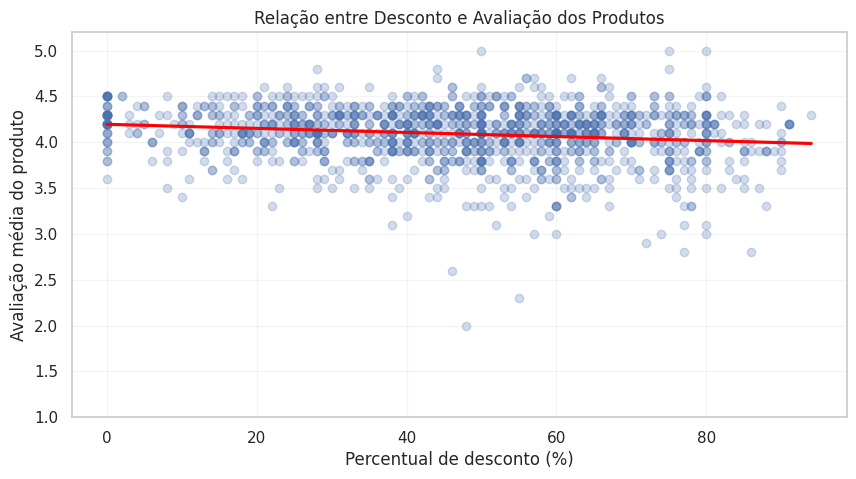

In [ ]:

# ETAPA 4.2 - Relação entre desconto e satisfação

# Selecionar somente registros com informações válidas
dados_correlacao = df_tratado[
    ["discount_percentage", "rating"]
].dropna()

# Calcular correlações
pearson = dados_correlacao[
    "discount_percentage"
].corr(dados_correlacao["rating"], method="pearson")

spearman = dados_correlacao[
    "discount_percentage"
].corr(dados_correlacao["rating"], method="spearman")

print("Produtos analisados:", len(dados_correlacao))
print(f"Correlação de Pearson: {pearson:.4f}")
print(f"Correlação de Spearman: {spearman:.4f}")

# Visualizar a relação entre as variáveis
plt.figure(figsize=(10, 5))

sns.regplot(
    data=dados_correlacao,
    x="discount_percentage",
    y="rating",
    scatter_kws={"alpha": 0.25},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Relação entre Desconto e Avaliação dos Produtos")
plt.xlabel("Percentual de desconto (%)")
plt.ylabel("Avaliação média do produto")
plt.ylim(1, 5.2)
plt.grid(alpha=0.2)
plt.show()


#### Insight 1 — Descontos e satisfação

A análise de 1.350 produtos identificou uma correlação negativa fraca entre o percentual de desconto e a avaliação média (Pearson = −0,1619; Spearman = −0,1497).

Os resultados sugerem que o desconto, isoladamente, não é um bom indicador da satisfação dos consumidores.

### 4.3 — Satisfação e engajamento por faixa de desconto


In [ ]:

# ETAPA 4.3 - Desconto x Satisfação x Engajamento

resumo_desconto = (
    df_tratado
    .groupby("faixa_desconto", observed=True)
    .agg(
        total_produtos=("product_id", "nunique"),
        avaliacao_media=("rating", "mean"),
        mediana_avaliacoes=("rating_count", "median"),
        desconto_medio=("discount_percentage", "mean")
    )
    .round(2)
)

display(resumo_desconto)


,total_produtos,avaliacao_media,mediana_avaliacoes,desconto_medio
faixa_desconto,,,,
1 - Baixo,350,4.16,7876.5,18.01
2 - Médio-baixo,339,4.09,4703.0,41.06
3 - Médio-alto,327,4.06,2449.0,55.90
4 - Alto,335,4.05,4415.0,73.36


#### Resultado — Faixas de desconto

A comparação dos produtos por faixa de desconto revelou uma redução gradual na avaliação média, passando de 4,16 estrelas entre os produtos com menores descontos para 4,05 estrelas entre aqueles com maiores descontos.

Em relação ao engajamento, os produtos com menores descontos apresentaram a maior mediana de avaliações (7.876,5), enquanto a menor mediana foi observada na faixa de desconto médio-alto (2.449).

Os resultados sugerem que descontos mais elevados não estão necessariamente associados a maiores níveis de satisfação ou engajamento.

Entretanto, essas associações não permitem estabelecer relações de causa e efeito. Fatores como categoria, características dos produtos e diferenças de visibilidade podem influenciar os resultados.

### 4.4 — Desconto e satisfação nas principais categorias

In [ ]:

# ETAPA 4.4 - Desconto e satisfação por categoria

# Selecionar as três maiores categorias
top_categorias = (
    df_tratado["categoria_principal"]
    .value_counts()
    .head(3)
    .index
)

df_top = df_tratado[
    df_tratado["categoria_principal"].isin(top_categorias)
].copy()

# Comparar os indicadores por categoria e faixa de desconto
analise_categoria_desconto = (
    df_top
    .groupby(
        ["categoria_principal", "faixa_desconto"],
        observed=True
    )
    .agg(
        total_produtos=("product_id", "nunique"),
        avaliacao_media=("rating", "mean"),
        mediana_avaliacoes=("rating_count", "median")
    )
    .round(2)
    .reset_index()
)

display(analise_categoria_desconto)


,categoria_principal,faixa_desconto,total_produtos,avaliacao_media,mediana_avaliacoes
0,Computers & Accessories,1 - Baixo,58,4.18,10796.5
1,Computers & Accessories,2 - Médio-baixo,75,4.17,9377.0
2,Computers & Accessories,3 - Médio-alto,104,4.20,5681.0
3,Computers & Accessories,4 - Alto,138,4.10,2977.0
4,Electronics,1 - Baixo,125,4.14,18998.0
5,Electronics,2 - Médio-baixo,97,4.14,6742.0
6,Electronics,3 - Médio-alto,106,3.99,2991.0
7,Electronics,4 - Alto,162,4.05,9254.5
8,Home & Kitchen,1 - Baixo,138,4.14,4485.5
9,Home & Kitchen,2 - Médio-baixo,164,4.02,2616.5


#### Resultado — Comparação por categoria

A análise das três maiores categorias revelou comportamentos distintos na relação entre descontos e satisfação dos consumidores.

A categoria Home & Kitchen apresentou redução progressiva da avaliação média conforme aumentaram as faixas de desconto, passando de 4,14 para 3,89 estrelas.

Computers & Accessories apresentou avaliações relativamente estáveis entre as faixas, enquanto Electronics demonstrou oscilações sem uma tendência contínua.

Esses resultados indicam a importância de analisar a estratégia de descontos por categoria, considerando que as associações observadas não estabelecem relações de causalidade.

A análise das sete faixas comerciais identificou avaliações médias relativamente próximas, variando entre 4,06 e 4,24 estrelas.

Os produtos da faixa de preço superior apresentaram a maior avaliação média (4,24), enquanto os produtos da faixa de menor preço registraram média de 4,06.

Os resultados sugerem uma associação positiva entre o nível de preço e a satisfação média dos consumidores, especialmente nas faixas mais elevadas. Entretanto, a diferença observada é pequena e não permite estabelecer uma relação de causalidade.

A análise será aprofundada considerando outros fatores, como categoria, desconto e quantidade de avaliações.

### 4.5 — Preço, satisfação e engajamento

In [ ]:

# ETAPA 4.5 - Preço x Satisfação x Engajamento

analise_preco = (
    df_tratado
    .groupby("faixa_preco_comercial", observed=True)
    .agg(
        total_produtos=("product_id", "nunique"),
        preco_medio=("discounted_price", "mean"),
        avaliacao_media=("rating", "mean"),
        mediana_avaliacoes=("rating_count", "median"),
        desconto_medio=("discount_percentage", "mean")
    )
    .round(2)
)

display(analise_preco)


,total_produtos,preco_medio,avaliacao_media,mediana_avaliacoes,desconto_medio
faixa_preco_comercial,,,,,
1 - Baixo,358,223.62,4.06,2958.5,55.17
2 - Médio-baixo,332,583.18,4.09,3644.5,49.54
3 - Médio,323,1433.05,4.08,7636.0,45.08
4 - Médio-alto,135,3128.24,4.08,3973.0,40.97
5 - Alto,84,7423.07,4.14,3827.5,35.17
6 - Muito alto,68,14599.07,4.16,18998.0,32.75
7 - Superior,51,33126.55,4.24,7109.0,31.41


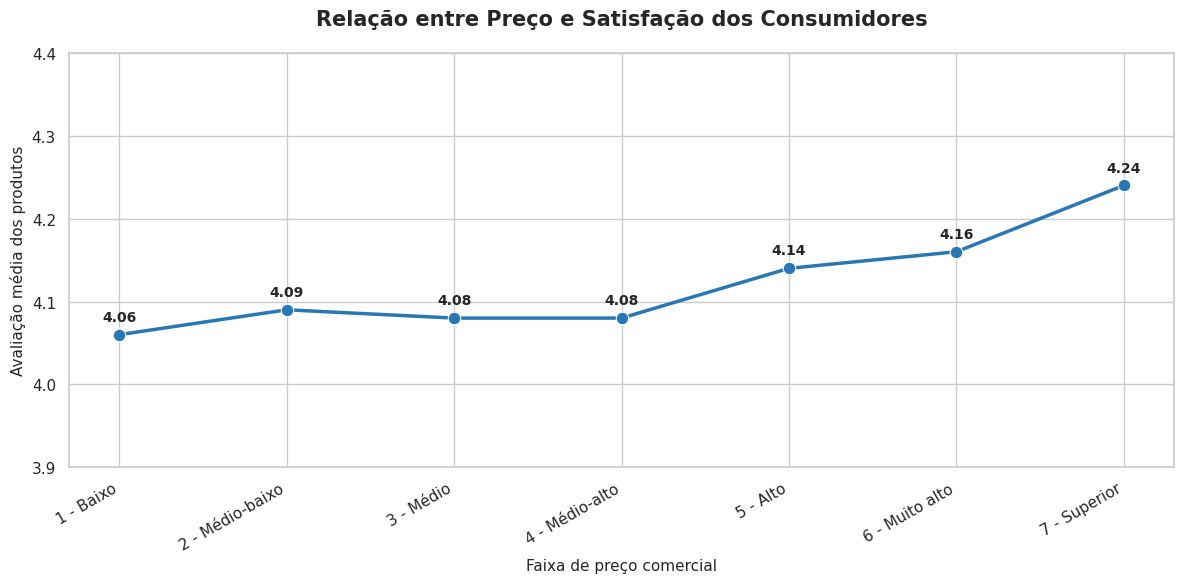

In [ ]:

# ETAPA 4.5 - Gráfico: Preço x Satisfação

import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo do gráfico
sns.set_theme(style="whitegrid")

# Utilizar o resumo já calculado
dados_grafico = analise_preco.reset_index()

# Criar gráfico
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=dados_grafico,
    x="faixa_preco_comercial",
    y="avaliacao_media",
    marker="o",
    markersize=9,
    linewidth=2.5,
    color="#2878B5"
)

# Exibir valores em cada ponto
for i, valor in enumerate(dados_grafico["avaliacao_media"]):
    plt.annotate(
        f"{valor:.2f}",
        (i, valor),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

# Títulos e eixos
plt.title(
    "Relação entre Preço e Satisfação dos Consumidores",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel("Faixa de preço comercial", fontsize=11)
plt.ylabel("Avaliação média dos produtos", fontsize=11)

# Aproximar a escala para visualizar as diferenças
plt.ylim(3.9, 4.4)

# Ajustar os rótulos
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()


In [ ]:

# ETAPA 4.6 - Produtos com riscos e oportunidades

# Definir limites com base nos quartis
q25 = df_tratado["rating_count"].quantile(0.25)
q75 = df_tratado["rating_count"].quantile(0.75)

print(f"Limite inferior de engajamento: {q25:.0f}")
print(f"Limite superior de engajamento: {q75:.0f}")

# Produtos com alto engajamento e baixa avaliação
produtos_atencao = df_tratado[
    (df_tratado["rating_count"] >= q75) &
    (df_tratado["rating"] < 4.0)
].copy()

# Produtos com boa avaliação e baixo engajamento
produtos_oportunidade = df_tratado[
    (df_tratado["rating_count"] <= q25) &
    (df_tratado["rating"] >= 4.3)
].copy()

# Resumo dos grupos encontrados
print("\nProdutos que merecem atenção:",
      len(produtos_atencao))

print("Produtos com oportunidade de divulgação:",
      len(produtos_oportunidade))


Limite inferior de engajamento: 1106
Limite superior de engajamento: 16020

Produtos que merecem atenção: 49
Produtos com oportunidade de divulgação: 81


In [ ]:

# Exibir produtos que merecem atenção
print("PRODUTOS COM ALTO ENGAJAMENTO E BAIXA AVALIAÇÃO")

display(
    produtos_atencao[
        [
            "product_name",
            "categoria_principal",
            "rating",
            "rating_count",
            "discount_percentage"
        ]
    ]
    .sort_values("rating_count", ascending=False)
    .head(10)
)

# Exibir produtos com oportunidades
print("\nPRODUTOS COM BOA AVALIAÇÃO E BAIXO ENGAJAMENTO")

display(
    produtos_oportunidade[
        [
            "product_name",
            "categoria_principal",
            "rating",
            "rating_count",
            "discount_percentage"
        ]
    ]
    .sort_values(
        ["rating", "rating_count"],
        ascending=[False, False]
    )
    .head(10)
)


PRODUTOS COM ALTO ENGAJAMENTO E BAIXA AVALIAÇÃO


,product_name,categoria_principal,rating,rating_count,discount_percentage
554,boAt Airdopes 121v2 in-Ear True Wireless Earbu...,Electronics,3.8,180998.0,57
548,boAt Airdopes 141 Bluetooth Truly Wireless in ...,Electronics,3.9,136954.0,67
908,Pigeon by Stovekraft Amaze Plus Electric Kettl...,Home & Kitchen,3.9,123365.0,48
605,Boult Audio Probass Curve Bluetooth Wireless i...,Electronics,3.8,103052.0,80
562,"JBL C50HI, Wired in Ear Headphones with Mic, O...",Electronics,3.9,92995.0,50
651,"JBL Tune 215BT, 16 Hrs Playtime with Quick Cha...",Electronics,3.7,87798.0,50
398,PTron Tangent Lite Bluetooth 5.0 Earphones wit...,Electronics,3.5,83996.0,67
569,Boult Audio BassBuds X1 in-Ear Wired Earphones...,Electronics,3.9,77027.0,67
649,Zebronics ZEB-COUNTY 3W Wireless Bluetooth Por...,Electronics,3.9,64705.0,45
917,"Prestige Electric Kettle PKOSS - 1500watts, St...",Home & Kitchen,3.9,63350.0,48



PRODUTOS COM BOA AVALIAÇÃO E BAIXO ENGAJAMENTO


,product_name,categoria_principal,rating,rating_count,discount_percentage
701,Amazon Basics Wireless Mouse | 2.4 GHz Connect...,Computers & Accessories,5.0,23.0,50
169,Syncwire LTG to USB Cable for Fast Charging Co...,Computers & Accessories,5.0,5.0,80
1087,"Oratech Coffee Frother electric, milk frother ...",Home & Kitchen,4.8,28.0,44
1112,Zuvexa USB Rechargeable Electric Foam Maker - ...,Home & Kitchen,4.7,54.0,62
534,"WeCool S5 Long Selfie Stick, with Large Reinfo...",Electronics,4.6,245.0,55
1005,Lint Remover Woolen Clothes Lint Extractor Bat...,Home & Kitchen,4.6,124.0,57
1175,Aquadpure Copper + Mineral RO+UV+UF 10 to 12 L...,Home & Kitchen,4.6,124.0,80
1102,"VRPRIME Lint Roller Lint Remover for Clothes, ...",Home & Kitchen,4.6,79.0,50
1179,Melbon VM-905 2000-Watt Room Heater (ISI Certi...,Home & Kitchen,4.6,9.0,67
1285,Cafe JEI French Press Coffee and Tea Maker 600...,Home & Kitchen,4.5,1065.0,27


### 4.6 — Identificação de riscos e oportunidades

**Objetivo:** identificar produtos com alto engajamento e baixa satisfação, bem como produtos com avaliações positivas e baixo engajamento.

**Metodologia:** segmentação dos produtos utilizando as notas médias e os quartis da quantidade de avaliações. Foram definidos critérios para identificar produtos que merecem atenção e possíveis oportunidades comerciais.

**Aplicação no negócio:** os resultados poderão orientar a priorização de análises de comentários, investigações sobre qualidade dos produtos e avaliações de oportunidades de divulgação.

**Limitação:** a quantidade de avaliações é utilizada como indicador indireto de engajamento, não representando necessariamente a visibilidade ou o volume de vendas do produto.

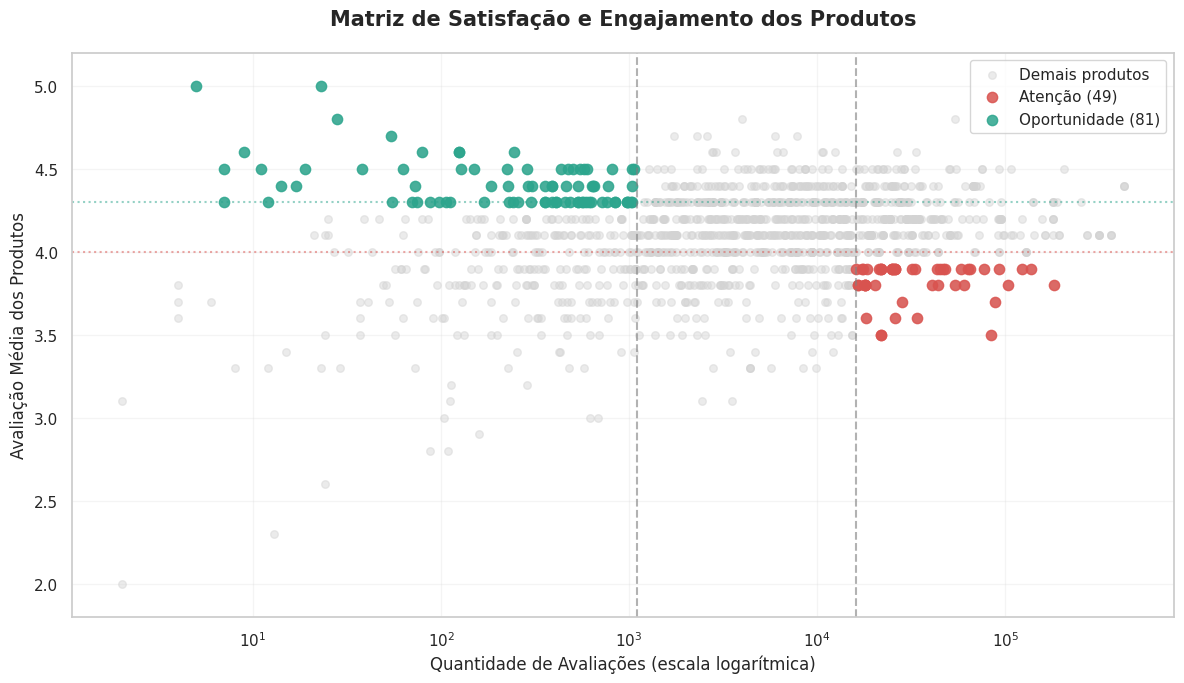

In [ ]:

# ETAPA 4.7 - Matriz de Satisfação x Engajamento

import matplotlib.pyplot as plt
import seaborn as sns

# Produtos com dados válidos
dados = df_tratado.dropna(
    subset=["rating", "rating_count"]
).copy()

plt.figure(figsize=(12, 7))

# Todos os produtos
plt.scatter(
    dados["rating_count"],
    dados["rating"],
    color="lightgray",
    alpha=0.45,
    s=30,
    label="Demais produtos"
)

# Produtos que merecem atenção
plt.scatter(
    produtos_atencao["rating_count"],
    produtos_atencao["rating"],
    color="#D9534F",
    alpha=0.85,
    s=55,
    label=f"Atenção ({len(produtos_atencao)})"
)

# Produtos com oportunidades potenciais
plt.scatter(
    produtos_oportunidade["rating_count"],
    produtos_oportunidade["rating"],
    color="#2CA58D",
    alpha=0.85,
    s=55,
    label=f"Oportunidade ({len(produtos_oportunidade)})"
)

# Limites de engajamento
plt.axvline(q25, color="gray", linestyle="--", alpha=0.6)
plt.axvline(q75, color="gray", linestyle="--", alpha=0.6)

# Limites de satisfação
plt.axhline(4.0, color="#D9534F",
            linestyle=":", alpha=0.5)

plt.axhline(4.3, color="#2CA58D",
            linestyle=":", alpha=0.5)

# Escala logarítmica no eixo X
plt.xscale("log")

plt.title(
    "Matriz de Satisfação e Engajamento dos Produtos",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xlabel("Quantidade de Avaliações (escala logarítmica)")
plt.ylabel("Avaliação Média dos Produtos")

plt.ylim(1.8, 5.2)
plt.grid(alpha=0.2)
plt.legend()

plt.tight_layout()
plt.show()


#### Resultado — Produtos de atenção e oportunidade

A análise identificou 49 produtos com alto engajamento e baixa avaliação, representando aproximadamente 3,6% do portfólio, e 81 produtos com boa avaliação e baixo engajamento, equivalentes a aproximadamente 6,0%.

Os produtos classificados como pontos de atenção apresentam notas inferiores a 4,0 e pelo menos 16.020 avaliações. Esses produtos são candidatos à investigação de possíveis problemas relatados pelos consumidores.

Por outro lado, os produtos com notas a partir de 4,3 e até 1.106 avaliações foram classificados como oportunidades potenciais. Entretanto, avaliações elevadas baseadas em poucas opiniões devem ser interpretadas com cautela.

Os resultados permitem estabelecer grupos prioritários para análises complementares de comentários e para a formulação de recomendações comerciais, sem pressupor relações de causalidade ou níveis de vendas e visibilidade não disponíveis na base.

#### Como interpretar a matriz de satisfação × engajamento

49 produtos em vermelho — Atenção

Possuem pelo menos 16.020 avaliações e nota inferior a 4,0. São produtos que merecem investigação, principalmente dos comentários negativos.




81 produtos em verde — Oportunidade potencial

Possuem até 1.106 avaliações e notas a partir de 4,3. São candidatos a análises de divulgação, mas precisamos considerar a confiabilidade de notas baseadas em poucas avaliações.




Demais produtos em cinza

Não atendem aos critérios específicos dos dois grupos. Isso não significa que estejam livres de problemas ou oportunidades.



Uma descoberta visual importante
Observe como a maior parte dos pontos se concentra entre 4,0 e 4,5 estrelas, mas com quantidades de avaliações bastante diferentes.

Isso reforça que satisfação e engajamento são dimensões distintas. Um produto pode ser bem avaliado e ter poucas avaliações, enquanto outro recebe milhares de avaliações e apresenta uma nota inferior.

Também ficou correta a utilização da escala logarítmica no eixo horizontal. Ela facilita a visualização de produtos com quantidades muito diferentes de avaliações.

### 4.8 — Riscos e oportunidades por categoria

In [ ]:

# ETAPA 4.8 - Riscos e oportunidades por categoria

# Contagem total de produtos por categoria
total_categoria = (
    df_tratado.groupby("categoria_principal")
    ["product_id"].nunique()
)

# Contagem dos produtos de atenção
atencao_categoria = (
    produtos_atencao.groupby("categoria_principal")
    ["product_id"].nunique()
)

# Contagem dos produtos de oportunidade
oportunidade_categoria = (
    produtos_oportunidade.groupby("categoria_principal")
    ["product_id"].nunique()
)

# Consolidar os resultados
resumo_riscos = pd.DataFrame({
    "total_produtos": total_categoria,
    "produtos_atencao": atencao_categoria,
    "produtos_oportunidade": oportunidade_categoria
}).fillna(0)

# Converter contagens para inteiros
resumo_riscos = resumo_riscos.astype(int)

# Calcular a proporção dentro de cada categoria
resumo_riscos["pct_atencao"] = (
    resumo_riscos["produtos_atencao"]
    / resumo_riscos["total_produtos"] * 100
).round(2)

resumo_riscos["pct_oportunidade"] = (
    resumo_riscos["produtos_oportunidade"]
    / resumo_riscos["total_produtos"] * 100
).round(2)

# Ordenar pela quantidade de produtos de atenção
resumo_riscos = resumo_riscos.sort_values(
    "produtos_atencao",
    ascending=False
)

display(resumo_riscos)


,total_produtos,produtos_atencao,produtos_oportunidade,pct_atencao,pct_oportunidade
categoria_principal,,,,,
Electronics,490,30,26,6.12,5.31
Home & Kitchen,448,12,33,2.68,7.37
Computers & Accessories,375,6,21,1.60,5.60
MusicalInstruments,2,1,0,50.00,0.00
Car & Motorbike,1,0,0,0.00,0.00
Health & PersonalCare,1,0,0,0.00,0.00
HomeImprovement,2,0,0,0.00,0.00
OfficeProducts,31,0,1,0.00,3.23
Toys & Games,1,0,0,0.00,0.00


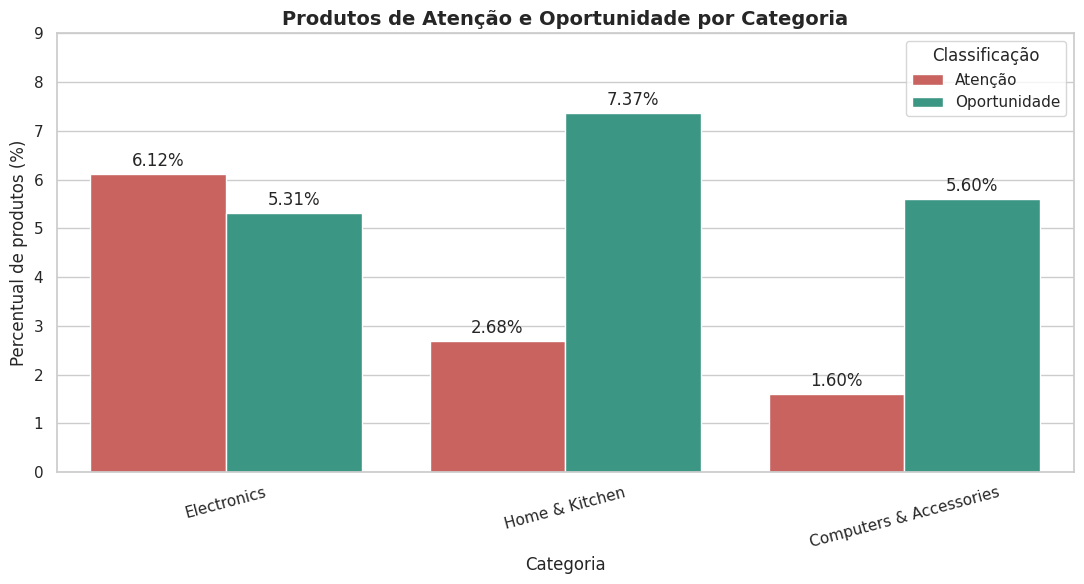

In [ ]:

# ETAPA 4.8 - Visualização de riscos e oportunidades

import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar as três maiores categorias
top3 = (
    resumo_riscos
    .sort_values("total_produtos", ascending=False)
    .head(3)
    .reset_index()
)

# Organizar os dados para o gráfico
dados_grafico = top3.melt(
    id_vars="categoria_principal",
    value_vars=["pct_atencao", "pct_oportunidade"],
    var_name="classificacao",
    value_name="percentual"
)

# Renomear classificações
dados_grafico["classificacao"] = (
    dados_grafico["classificacao"].replace({
        "pct_atencao": "Atenção",
        "pct_oportunidade": "Oportunidade"
    })
)

# Criar gráfico
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=dados_grafico,
    x="categoria_principal",
    y="percentual",
    hue="classificacao",
    palette={
        "Atenção": "#D9534F",
        "Oportunidade": "#2CA58D"
    }
)

# Mostrar percentuais nas barras
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.title(
    "Produtos de Atenção e Oportunidade por Categoria",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Categoria")
plt.ylabel("Percentual de produtos (%)")
plt.ylim(0, 9)
plt.legend(title="Classificação")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


#### Resultado — Riscos e oportunidades por categoria

A análise identificou que a categoria Electronics concentra a maior quantidade de produtos classificados como pontos de atenção, totalizando 30 produtos, equivalentes a 6,12% da categoria e aproximadamente 61,2% de todos os produtos classificados nesse grupo.

A categoria Home & Kitchen apresentou a maior proporção de oportunidades potenciais entre as três categorias principais, com 33 produtos (7,37% da categoria).

Por outro lado, Computers & Accessories apresentou a menor proporção de produtos de atenção entre as categorias principais (1,60%).

**Recomendações preliminares:**

- Priorizar a investigação dos comentários dos produtos de atenção da categoria Electronics.
- Avaliar oportunidades de divulgação para produtos bem avaliados e com baixo engajamento em Home & Kitchen.
- Aprofundar a análise dos fatores associados à satisfação em Computers & Accessories.

Essas recomendações são exploratórias e deverão ser complementadas por análises estatísticas e de comentários dos consumidores.

## 5. Análise de correlação

### 5.1 — Matriz de correlação de Pearson


Matriz de Correlação de Pearson:


,actual_price,discounted_price,discount_percentage,economia_valor,rating,log_rating_count
actual_price,1.000,0.962,-0.112,0.911,0.127,0.063
discounted_price,0.962,1.000,-0.237,0.765,0.126,0.085
discount_percentage,-0.112,-0.237,1.000,0.094,-0.162,-0.133
economia_valor,0.911,0.765,0.094,1.000,0.110,0.022
rating,0.127,0.126,-0.162,0.110,1.000,0.247
log_rating_count,0.063,0.085,-0.133,0.022,0.247,1.000


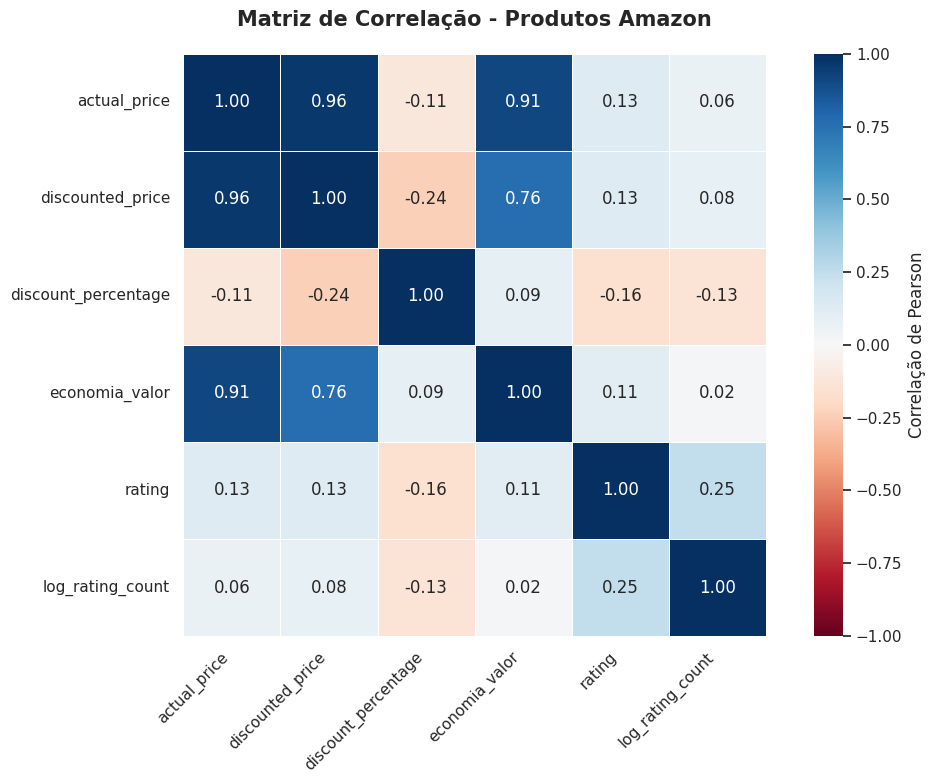

In [ ]:

# ETAPA 5.1 - Análise estatística e correlação

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar variáveis numéricas relevantes
variaveis = [
    "actual_price",
    "discounted_price",
    "discount_percentage",
    "economia_valor",
    "rating",
    "log_rating_count"
]

# Criar base auxiliar para análise
df_correlacao = df_tratado[variaveis].copy()

# Calcular correlação de Pearson
matriz_correlacao = df_correlacao.corr(
    method="pearson"
)

# Exibir os coeficientes
print("Matriz de Correlação de Pearson:")
display(matriz_correlacao.round(3))

# Criar gráfico de calor (Heatmap)
plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlação de Pearson"}
)

plt.title(
    "Matriz de Correlação - Produtos Amazon",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### 5.2 — Matriz de correlação de Spearman


Matriz de Correlação de Spearman:


,actual_price,discounted_price,discount_percentage,economia_valor,rating,log_rating_count
actual_price,1.000,0.934,-0.065,0.894,0.032,0.109
discounted_price,0.934,1.000,-0.367,0.717,0.077,0.146
discount_percentage,-0.065,-0.367,1.000,0.290,-0.150,-0.131
economia_valor,0.894,0.717,0.290,1.000,-0.020,0.043
rating,0.032,0.077,-0.150,-0.020,1.000,0.193
log_rating_count,0.109,0.146,-0.131,0.043,0.193,1.000


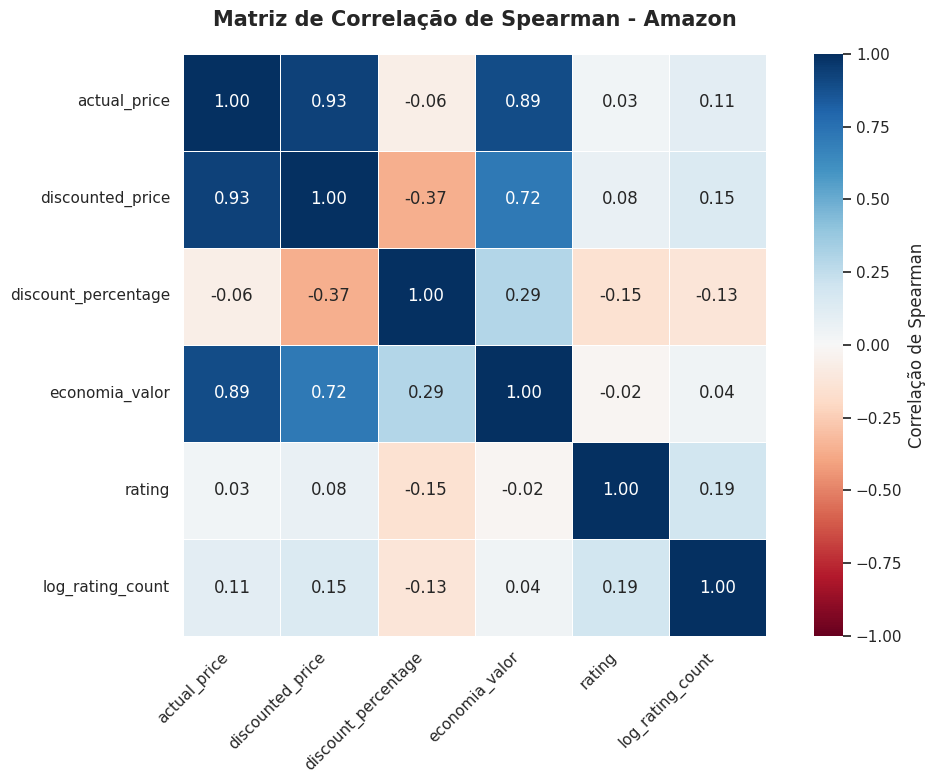

In [ ]:

# ETAPA 5.2 - Matriz de Correlação de Spearman

# Utilizar a mesma base da análise de Pearson
matriz_spearman = df_correlacao.corr(
    method="spearman"
)

print("Matriz de Correlação de Spearman:")
display(matriz_spearman.round(3))

# Criar o heatmap de Spearman
plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz_spearman,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlação de Spearman"}
)

plt.title(
    "Matriz de Correlação de Spearman - Amazon",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### 5.3 — Comparação entre Pearson e Spearman

Foram aplicados os métodos de correlação de Pearson e Spearman para investigar associações entre preços, descontos, satisfação e engajamento dos consumidores.

Os resultados demonstraram uma associação negativa fraca entre o percentual de desconto e a avaliação dos produtos, com coeficientes de −0,162 (Pearson) e −0,150 (Spearman).

A relação entre satisfação e engajamento também apresentou associação fraca, porém positiva, com coeficientes de 0,247 (Pearson) e 0,193 (Spearman).

A comparação identificou ainda uma associação negativa entre o preço promocional e o percentual de desconto, mais pronunciada no método de Spearman (−0,367).

**Conclusão:** as variáveis comerciais analisadas apresentam associações limitadas com a satisfação dos consumidores. Os resultados reforçam a importância de investigar outras características dos produtos e as percepções registradas nos comentários.

As correlações também auxiliarão na seleção dos atributos para o Machine Learning, considerando a necessidade de evitar redundância entre variáveis matematicamente relacionadas.

## 6. Segmentação não supervisionada com K-Means

### 6.1 — Preparação da base de modelagem


In [ ]:

# ETAPA 6.1 - Preparação para o K-Means

import numpy as np
import pandas as pd

# Selecionar as variáveis relevantes
variaveis_ml = [
    "discounted_price",
    "discount_percentage",
    "rating",
    "log_rating_count"
]

# Criar base exclusiva para Machine Learning
df_ml = df_tratado[
    ["product_id"] + variaveis_ml
].copy()

# Verificar valores ausentes
print("Valores ausentes antes do tratamento:")
print(df_ml.isnull().sum())

# Remover registros incompletos apenas da base do modelo
df_ml = df_ml.dropna(subset=variaveis_ml).copy()

# Criar transformação logarítmica do preço
df_ml["log_preco"] = np.log1p(
    df_ml["discounted_price"]
)

# Exibir a base preparada
print("\nProdutos disponíveis para o K-Means:", len(df_ml))

display(df_ml.head())


Valores ausentes antes do tratamento:
product_id             0
discounted_price       0
discount_percentage    0
rating                 1
log_rating_count       2
dtype: int64

Produtos disponíveis para o K-Means: 1348


,product_id,discounted_price,discount_percentage,rating,log_rating_count,log_preco
0,B098NS6PVG,199.0,43,4.0,10.691831,5.298317
1,B096MSW6CT,199.0,90,3.9,8.978282,5.298317
2,B08CF3B7N1,154.0,61,4.2,9.735424,5.043425
3,B08Y1TFSP6,149.0,85,3.9,10.121498,5.010635
4,B08DDRGWTJ,229.0,23,4.3,10.322593,5.438079


### 6.2 — Padronização das variáveis (StandardScaler)


In [ ]:

# ETAPA 6.2 - Padronização das variáveis para o K-Means

from sklearn.preprocessing import StandardScaler

# Selecionar as variáveis utilizadas no modelo
features = [
    "log_preco",
    "discount_percentage",
    "rating",
    "log_rating_count"
]

# Criar base com os atributos selecionados
X = df_ml[features].copy()

# Inicializar o StandardScaler
scaler = StandardScaler()

# Aplicar a padronização
X_scaled = scaler.fit_transform(X)

# Converter o resultado para DataFrame
df_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df_ml.index
)

# Visualizar os primeiros registros
display(df_scaled.head())

# Verificar média e desvio-padrão
print("\nMédia das variáveis padronizadas:")
display(df_scaled.mean().round(2))

print("\nDesvio-padrão das variáveis padronizadas:")
display(df_scaled.std(ddof=0).round(2))

# Confirmar dimensões
print("\nDimensões da base padronizada:", df_scaled.shape)


,log_preco,discount_percentage,rating,log_rating_count
0,-1.141594,-0.169614,-0.311793,1.204054
1,-1.141594,2.006139,-0.650741,0.362515
2,-1.320017,0.663653,0.366105,0.734354
3,-1.342970,1.774676,-0.650741,0.923958
4,-1.043762,-1.095466,0.705054,1.022717



Média das variáveis padronizadas:


,0
log_preco,-0.0
discount_percentage,0.0
rating,-0.0
log_rating_count,0.0



Desvio-padrão das variáveis padronizadas:


,0
log_preco,1.0
discount_percentage,1.0
rating,1.0
log_rating_count,1.0



Dimensões da base padronizada: (1348, 4)


### 6.3 — Escolha do número de clusters

In [ ]:

# ETAPA 6.3 - Avaliação do número de clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []

# Testar diferentes quantidades de clusters
for k in range(2, 9):

    # Inicializar e treinar o K-Means
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(X_scaled)

    # Calcular Silhouette Score
    silhouette = silhouette_score(
        X_scaled,
        clusters
    )

    # Armazenar resultados
    resultados.append({
        "clusters": k,
        "inercia": kmeans.inertia_,
        "silhouette": silhouette
    })

# Criar tabela de resultados
df_resultados_kmeans = pd.DataFrame(resultados)

display(df_resultados_kmeans.round(4))


,clusters,inercia,silhouette
0,2,4031.3320,0.2353
1,3,3297.8414,0.2265
2,4,2824.9298,0.2320
3,5,2437.2223,0.2358
4,6,2235.0249,0.2335
5,7,2061.1679,0.2300
6,8,1936.3804,0.2173


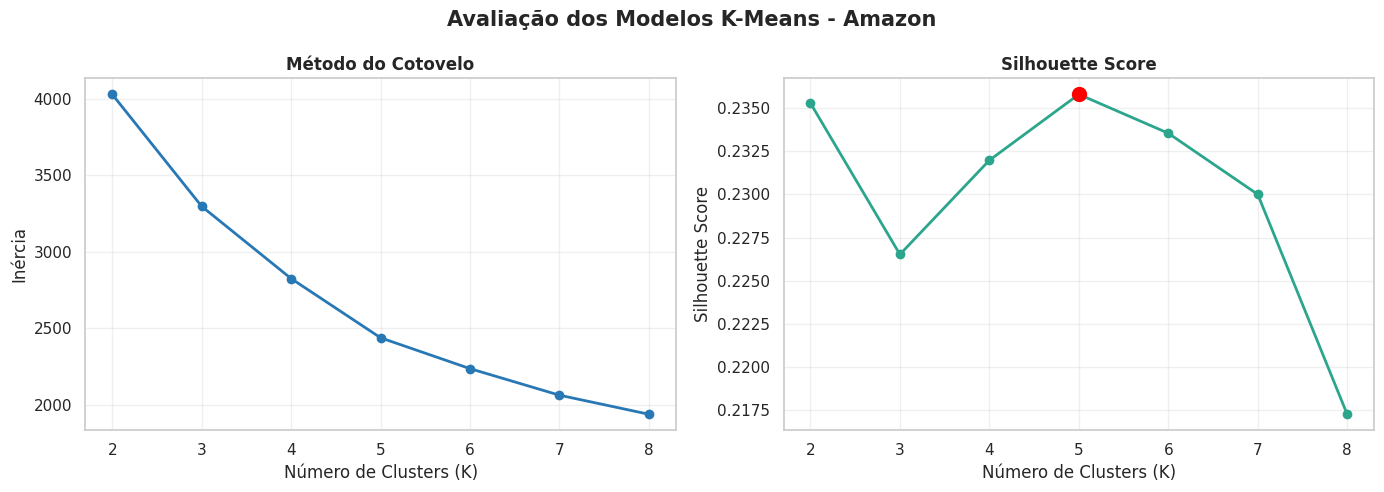

In [ ]:

# ETAPA 6.3 - Visualização da avaliação do K-Means

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1 - Método do Cotovelo
axes[0].plot(
    df_resultados_kmeans["clusters"],
    df_resultados_kmeans["inercia"],
    marker="o",
    linewidth=2,
    color="#2878B5"
)

axes[0].set_title("Método do Cotovelo", fontweight="bold")
axes[0].set_xlabel("Número de Clusters (K)")
axes[0].set_ylabel("Inércia")
axes[0].grid(alpha=0.3)

# Gráfico 2 - Silhouette Score
axes[1].plot(
    df_resultados_kmeans["clusters"],
    df_resultados_kmeans["silhouette"],
    marker="o",
    linewidth=2,
    color="#2CA58D"
)

axes[1].set_title("Silhouette Score", fontweight="bold")
axes[1].set_xlabel("Número de Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

# Destacar o maior Silhouette
melhor = df_resultados_kmeans.loc[
    df_resultados_kmeans["silhouette"].idxmax()
]

axes[1].scatter(
    melhor["clusters"],
    melhor["silhouette"],
    color="red",
    s=100,
    zorder=5
)

plt.suptitle(
    "Avaliação dos Modelos K-Means - Amazon",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### 6.4 — Comparação dos modelos candidatos

In [ ]:

# ETAPA 6.4 - Comparação dos modelos K-Means

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Base de produtos para interpretar os resultados
base_perfil = df_ml.merge(
    df_tratado[["product_id", "rating_count"]],
    on="product_id",
    how="left",
    validate="one_to_one"
).reset_index(drop=True)

# Armazenar modelos e resultados
modelos_kmeans = {}
perfis_kmeans = {}

for k in [2, 5]:

    # Treinar modelo
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = modelo.fit_predict(X_scaled)

    # Armazenar modelo
    modelos_kmeans[k] = modelo

    # Associar classificação aos produtos
    resultado = base_perfil.copy()
    resultado["cluster"] = labels

    # Calcular indicadores por cluster
    perfil = (
        resultado
        .groupby("cluster")
        .agg(
            total_produtos=("product_id", "count"),
            preco_mediano=("discounted_price", "median"),
            desconto_medio=("discount_percentage", "mean"),
            avaliacao_media=("rating", "mean"),
            mediana_avaliacoes=("rating_count", "median")
        )
        .round(2)
    )

    perfis_kmeans[k] = perfil

    print(f"\n===== MODELO COM {k} CLUSTERS =====")

    print(
        "Silhouette Score:",
        round(silhouette_score(X_scaled, labels), 4)
    )

    display(perfil)



===== MODELO COM 2 CLUSTERS =====
Silhouette Score: 0.2353


,total_produtos,preco_mediano,desconto_medio,avaliacao_media,mediana_avaliacoes
cluster,,,,,
0,747,1499.0,34.73,4.19,10443.0
1,601,399.0,61.50,3.97,1313.0



===== MODELO COM 5 CLUSTERS =====
Silhouette Score: 0.2358


,total_produtos,preco_mediano,desconto_medio,avaliacao_media,mediana_avaliacoes
cluster,,,,,
0,182,599.0,56.30,3.58,530.5
1,267,849.0,19.63,4.19,6531.0
2,362,699.0,59.96,4.17,20025.5
3,265,389.0,62.85,4.19,900.0
4,272,8749.0,33.29,4.14,6707.5


### 6.5 — Interpretação e rotulagem dos clusters

In [ ]:

# ETAPA 6.5 - Associar os clusters aos produtos

# Recuperar o modelo K = 5 já treinado
modelo_final = modelos_kmeans[5]

# Criar tabela de classificação
df_clusters = df_ml[["product_id"]].copy()

# Adicionar o cluster previsto para cada produto
df_clusters["cluster"] = modelo_final.labels_

# Verificar se cada produto tem apenas uma classificação
print("Produtos classificados:", len(df_clusters))

print(
    "IDs duplicados:",
    df_clusters["product_id"].duplicated().sum()
)

# Adicionar a classificação na base tratada
df_tratado_clusters = df_tratado.merge(
    df_clusters,
    on="product_id",
    how="left",
    validate="one_to_one"
)

# Criar nomes interpretáveis para os grupos
nomes_clusters = {
    0: "Menor satisfação",
    1: "Boa satisfação e desconto reduzido",
    2: "Alto engajamento e desconto elevado",
    3: "Preço baixo e boa satisfação",
    4: "Preço elevado"
}

df_tratado_clusters["perfil_cluster"] = (
    df_tratado_clusters["cluster"]
    .map(nomes_clusters)
    .fillna("Não classificado")
)

# Conferir a classificação
display(
    df_tratado_clusters[
        [
            "product_id",
            "product_name",
            "rating",
            "rating_count",
            "cluster",
            "perfil_cluster"
        ]
    ].head(10)
)

# Quantidade de produtos por perfil
print("\nDistribuição dos produtos:")
display(
    df_tratado_clusters["perfil_cluster"]
    .value_counts()
)

# Produtos que não participaram do modelo
print(
    "\nProdutos não classificados:",
    df_tratado_clusters["cluster"].isna().sum()
)


Produtos classificados: 1348
IDs duplicados: 0


,product_id,product_name,rating,rating_count,cluster,perfil_cluster
0,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,4.0,43994.0,2.0,Alto engajamento e desconto elevado
1,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,3.9,7928.0,2.0,Alto engajamento e desconto elevado
2,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,4.2,16905.0,2.0,Alto engajamento e desconto elevado
3,B08Y1TFSP6,pTron Solero TB301 3A Type-C Data and Fast Cha...,3.9,24871.0,2.0,Alto engajamento e desconto elevado
4,B08DDRGWTJ,MI Usb Type-C Cable Smartphone (Black),4.3,30411.0,1.0,Boa satisfação e desconto reduzido
5,B008IFXQFU,"TP-Link USB WiFi Adapter for PC(TL-WN725N), N1...",4.2,179691.0,2.0,Alto engajamento e desconto elevado
6,B082LZGK39,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,4.0,43994.0,1.0,Boa satisfação e desconto reduzido
7,B08CF3D7QR,Portronics Konnect L POR-1081 Fast Charging 3A...,4.3,13391.0,2.0,Alto engajamento e desconto elevado
8,B07KSMBL2H,AmazonBasics Flexible Premium HDMI Cable (Blac...,4.4,426973.0,2.0,Alto engajamento e desconto elevado
9,B09KLVMZ3B,Portronics Konnect L 1.2M POR-1401 Fast Chargi...,4.1,4768.0,2.0,Alto engajamento e desconto elevado



Distribuição dos produtos:


,count
perfil_cluster,
Alto engajamento e desconto elevado,362
Preço elevado,272
Boa satisfação e desconto reduzido,267
Preço baixo e boa satisfação,265
Menor satisfação,182
Não classificado,3



Produtos não classificados: 3


### 6.6 — Perfis de clusters por categoria

In [ ]:

# ETAPA 6.6 - Distribuição dos clusters por categoria

# Selecionar as três maiores categorias
top3_categorias = (
    df_tratado_clusters["categoria_principal"]
    .value_counts()
    .head(3)
    .index
)

# Filtrar produtos das categorias selecionadas
df_cluster_categoria = df_tratado_clusters[
    df_tratado_clusters["categoria_principal"].isin(
        top3_categorias
    )
].copy()

# Quantidade de produtos por categoria e cluster
tabela_clusters = pd.crosstab(
    df_cluster_categoria["categoria_principal"],
    df_cluster_categoria["perfil_cluster"]
)

print("Quantidade de produtos por categoria e cluster:")
display(tabela_clusters)

# Calcular percentual dentro de cada categoria
tabela_percentual = (
    tabela_clusters
    .div(tabela_clusters.sum(axis=1), axis=0)
    * 100
).round(2)

print("\nDistribuição percentual por categoria:")
display(tabela_percentual)


Quantidade de produtos por categoria e cluster:


perfil_cluster,Alto engajamento e desconto elevado,Boa satisfação e desconto reduzido,Menor satisfação,Não classificado,Preço baixo e boa satisfação,Preço elevado
categoria_principal,,,,,,
Computers & Accessories,150,66,32,2,106,19
Electronics,157,51,65,0,73,144
Home & Kitchen,49,120,84,1,85,109



Distribuição percentual por categoria:


perfil_cluster,Alto engajamento e desconto elevado,Boa satisfação e desconto reduzido,Menor satisfação,Não classificado,Preço baixo e boa satisfação,Preço elevado
categoria_principal,,,,,,
Computers & Accessories,40.00,17.60,8.53,0.53,28.27,5.07
Electronics,32.04,10.41,13.27,0.00,14.90,29.39
Home & Kitchen,10.94,26.79,18.75,0.22,18.97,24.33


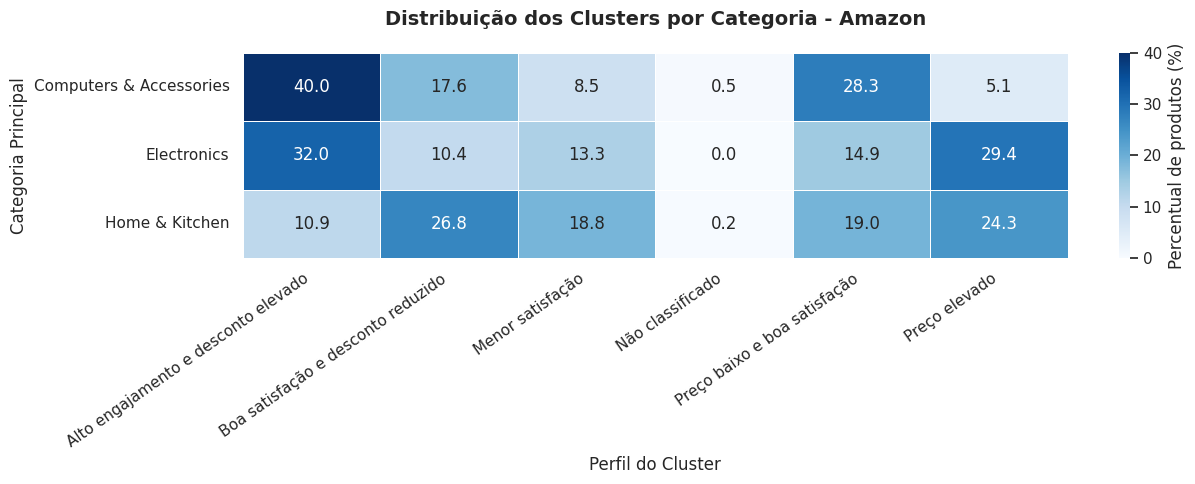

In [ ]:

# ETAPA 6.6 - Heatmap dos clusters por categoria

plt.figure(figsize=(13, 5))

sns.heatmap(
    tabela_percentual,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Percentual de produtos (%)"}
)

plt.title(
    "Distribuição dos Clusters por Categoria - Amazon",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("Perfil do Cluster")
plt.ylabel("Categoria Principal")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


#### 6.6 — Interpretação dos clusters por categoria

A distribuição dos clusters revelou diferenças entre as três principais categorias do portfólio.

Computers & Accessories apresentou a maior concentração de produtos no cluster de alto engajamento e desconto elevado (40,00%), seguida por Electronics (32,04%).

Em Electronics, também foi observada uma participação expressiva do cluster de preço elevado (29,39%).

Home & Kitchen apresentou a maior proporção de produtos no cluster de menor satisfação (18,75%) entre as três categorias analisadas, indicando uma oportunidade de aprofundamento da análise dos comentários dos consumidores.

Os resultados demonstram que a segmentação pode apoiar a identificação de perfis comerciais distintos e orientar investigações específicas por categoria.

Como os agrupamentos foram construídos utilizando preço, desconto, satisfação e engajamento, os resultados deverão ser interpretados como perfis exploratórios, e não como evidência de causalidade.

### 6.7 — Estabilidade de inicialização (ARI)

In [ ]:

# ETAPA 6.7 - Teste de estabilidade do K-Means

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Recuperar o modelo de referência com K = 5
modelo_referencia = modelos_kmeans[5]
clusters_referencia = modelo_referencia.labels_

# Testar diferentes inicializações
sementes = [0, 1, 7, 21, 42, 99, 123]

resultados_estabilidade = []

for semente in sementes:

    modelo_teste = KMeans(
        n_clusters=5,
        random_state=semente,
        n_init=10
    )

    clusters_teste = modelo_teste.fit_predict(X_scaled)

    # Comparar com a classificação de referência
    ari = adjusted_rand_score(
        clusters_referencia,
        clusters_teste
    )

    resultados_estabilidade.append({
        "semente": semente,
        "ARI": ari,
        "inercia": modelo_teste.inertia_
    })

# Consolidar os resultados
df_estabilidade = pd.DataFrame(resultados_estabilidade)

display(df_estabilidade.round(4))

print(
    "\nARI médio:",
    round(df_estabilidade["ARI"].mean(), 4)
)

print(
    "Menor ARI:",
    round(df_estabilidade["ARI"].min(), 4)
)


,semente,ARI,inercia
0,0,0.9875,2437.2365
1,1,0.9872,2437.2267
2,7,0.9904,2437.2192
3,21,0.9667,2437.3601
4,42,1.0000,2437.2223
5,99,0.9940,2437.1884
6,123,0.9700,2437.3368



ARI médio: 0.9851
Menor ARI: 0.9667


### 6.8 — Qualidade, estabilidade e limitações do K-Means

Foi desenvolvido um modelo de agrupamento não supervisionado utilizando o algoritmo K-Means, com o objetivo de identificar segmentos de produtos com características semelhantes de preço, desconto, satisfação e engajamento.

As variáveis selecionadas foram `log_preco`, `discount_percentage`, `rating` e `log_rating_count`, previamente padronizadas utilizando `StandardScaler`.

Foram avaliadas soluções entre dois e oito clusters por meio da inércia e do Silhouette Score. A configuração com cinco clusters apresentou o maior Silhouette Score (0,2358), embora a diferença em relação às demais configurações tenha sido pequena.

Para avaliar a estabilidade do modelo, foram realizadas sete execuções com diferentes sementes aleatórias. A comparação com o modelo de referência, utilizando o Adjusted Rand Index (ARI), apresentou média de 0,9851 e valor mínimo de 0,9667, indicando elevada consistência dos agrupamentos entre inicializações.

A solução com cinco clusters foi selecionada por combinar estabilidade e possibilidade de interpretação comercial dos grupos.

**Limitações:** o Silhouette Score relativamente baixo indica sobreposição entre os clusters. Além disso, o teste de ARI avaliou a estabilidade entre inicializações sobre a mesma base, não a estabilidade diante de alterações na amostra.

Os resultados deverão ser utilizados como segmentação exploratória, auxiliando análises de portfólio e recomendações comerciais, sem pressupor relações de causalidade.

O modelo classificou 1.348 produtos, preservando três produtos sem classificação devido à ausência de informações necessárias à modelagem.

## 7. Customer Insights — análise de texto (NLP)

### 7.1 — Avaliação da granularidade dos comentários

A base pode armazenar diversos comentários dentro de um mesmo campo por produto. Antes de analisar sentimentos, verifica-se se os identificadores, títulos e conteúdos podem ser separados de modo consistente. Como a correspondência entre essas listas não é confiável, **não se atribuem notas ou sentimentos a comentários individuais**: o trabalho utiliza o texto agregado de cada produto.

In [ ]:

# ETAPA 7.1 - Preparação dos comentários

import pandas as pd

# Utilizar a base original para preservar as avaliações
df_reviews = df[
    ["product_id", "review_id", "review_title", "review_content"]
].copy()

# Separar os identificadores de avaliações
df_reviews["review_id"] = (
    df_reviews["review_id"].str.split(",")
)

# Separar os títulos
df_reviews["review_title"] = (
    df_reviews["review_title"].str.split(",")
)

# Separar os conteúdos
df_reviews["review_content"] = (
    df_reviews["review_content"].str.split(",")
)

# Verificar a quantidade de elementos por registro
df_reviews["qtd_ids"] = df_reviews["review_id"].str.len()
df_reviews["qtd_titulos"] = df_reviews["review_title"].str.len()
df_reviews["qtd_comentarios"] = df_reviews["review_content"].str.len()

# Verificar correspondência entre as listas
df_reviews["listas_compativeis"] = (
    (df_reviews["qtd_ids"] == df_reviews["qtd_titulos"]) &
    (df_reviews["qtd_ids"] == df_reviews["qtd_comentarios"])
)

print("Registros com listas compatíveis:",
      df_reviews["listas_compativeis"].sum())

print("Registros com listas incompatíveis:",
      (~df_reviews["listas_compativeis"]).sum())

display(
    df_reviews[
        ["qtd_ids", "qtd_titulos",
         "qtd_comentarios", "listas_compativeis"]
    ].head()
)


Registros com listas compatíveis: 165
Registros com listas incompatíveis: 1300


,qtd_ids,qtd_titulos,qtd_comentarios,listas_compativeis
0,8,8,10,False
1,8,8,15,False
2,8,8,8,True
3,8,8,10,False
4,8,8,20,False


### 7.2 — Análise de sentimentos com VADER


**Dependência de NLP:** instale `vaderSentiment` via `pip install -r requirements.txt` antes de executar o notebook. No Google Colab, execute `!pip install vaderSentiment` somente se o pacote ainda não estiver disponível.

In [ ]:

# ETAPA 7.2 - Análise de sentimentos dos comentários

import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Criar base para análise textual
df_sentimentos = df_tratado_clusters[
    [
        "product_id",
        "categoria_principal",
        "rating",
        "review_content"
    ]
].copy()

# Preparar os textos
df_sentimentos["review_content"] = (
    df_sentimentos["review_content"]
    .fillna("")
    .astype(str)
)

# Inicializar o analisador VADER
analisador = SentimentIntensityAnalyzer()

# Calcular a polaridade dos comentários
df_sentimentos["sentiment_score"] = (
    df_sentimentos["review_content"]
    .apply(
        lambda texto: analisador.polarity_scores(texto)["compound"]
    )
)

# Classificar os sentimentos
def classificar_sentimento(score):
    if score >= 0.05:
        return "Positivo"
    elif score <= -0.05:
        return "Negativo"
    else:
        return "Neutro"

df_sentimentos["sentimento"] = (
    df_sentimentos["sentiment_score"]
    .apply(classificar_sentimento)
)

# Verificar os resultados
print("Distribuição dos sentimentos:")
display(df_sentimentos["sentimento"].value_counts())

print("\nExemplo dos produtos classificados:")
display(
    df_sentimentos[
        [
            "product_id",
            "rating",
            "sentiment_score",
            "sentimento"
        ]
    ].head(10)
)


Distribuição dos sentimentos:


,count
sentimento,
Positivo,1286
Negativo,59
Neutro,6



Exemplo dos produtos classificados:


,product_id,rating,sentiment_score,sentimento
0,B098NS6PVG,4.0,0.9853,Positivo
1,B096MSW6CT,3.9,0.7089,Positivo
2,B08CF3B7N1,4.2,0.9955,Positivo
3,B08Y1TFSP6,3.9,0.6611,Positivo
4,B08DDRGWTJ,4.3,0.9334,Positivo
5,B008IFXQFU,4.2,0.9867,Positivo
6,B082LZGK39,4.0,0.9853,Positivo
7,B08CF3D7QR,4.3,0.9775,Positivo
8,B07KSMBL2H,4.4,0.9945,Positivo
9,B09KLVMZ3B,4.1,0.9738,Positivo


### 7.3 — Extração de expressões recorrentes

In [ ]:

# ETAPA 7.3 - Identificação de temas frequentes

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import (
    CountVectorizer,
    ENGLISH_STOP_WORDS
)

# Preservar palavras de negação
stopwords = list(
    ENGLISH_STOP_WORDS.difference({"not", "no", "never"})
)

def extrair_temas(sentimento, min_freq):

    # Selecionar os textos da classificação
    textos = df_sentimentos.loc[
        df_sentimentos["sentimento"] == sentimento,
        "review_content"
    ].fillna("")

    # Identificar expressões de duas palavras
    vetor = CountVectorizer(
        stop_words=stopwords,
        ngram_range=(2, 2),
        min_df=min_freq,
        binary=True
    )

    matriz = vetor.fit_transform(textos)

    # Criar tabela de expressões
    resultado = pd.DataFrame({
        "sentimento": sentimento,
        "expressao": vetor.get_feature_names_out(),
        "produtos_mencionando": np.asarray(
            matriz.sum(axis=0)
        ).ravel()
    })

    return (
        resultado
        .sort_values(
            "produtos_mencionando",
            ascending=False
        )
        .head(15)
    )

# Expressões mais comuns por classificação
temas_positivos = extrair_temas("Positivo", 5)
temas_negativos = extrair_temas("Negativo", 2)

print("EXPRESSÕES EM TEXTOS POSITIVOS")
display(temas_positivos)

print("\nEXPRESSÕES EM TEXTOS NEGATIVOS")
display(temas_negativos)


EXPRESSÕES EM TEXTOS POSITIVOS


,sentimento,expressao,produtos_mencionando
1253,Positivo,good product,570
3452,Positivo,value money,351
2552,Positivo,product good,348
2687,Positivo,quality good,323
1257,Positivo,good quality,284
924,Positivo,easy use,253
2009,Positivo,nice product,244
2126,Positivo,not good,210
622,Positivo,com images,201
97,Positivo,_sy88 jpg,201



EXPRESSÕES EM TEXTOS NEGATIVOS


,sentimento,expressao,produtos_mencionando
187,Negativo,good product,18
402,Negativo,product good,15
328,Negativo,not good,13
188,Negativo,good quality,13
408,Negativo,product not,11
142,Negativo,easy use,11
344,Negativo,not working,10
86,Negativo,com images,9
223,Negativo,https media,9
429,Negativo,quality not,9


### 7.4 — Limpeza de URLs e reavaliação do sentimento

In [ ]:

# ETAPA 7.4 - Limpeza final dos comentários

import re

# Preservar o texto original
df_sentimentos["texto_limpo"] = (
    df_sentimentos["review_content"]
    .fillna("")
    .astype(str)
    .str.replace(
        r"https?://[^\s,]+",
        " ",
        regex=True
    )
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Recalcular sentimento após remover os links
df_sentimentos["sentiment_score"] = (
    df_sentimentos["texto_limpo"]
    .apply(
        lambda texto: analisador.polarity_scores(texto)["compound"]
    )
)

df_sentimentos["sentimento"] = (
    df_sentimentos["sentiment_score"]
    .apply(classificar_sentimento)
)

print("Distribuição atualizada dos sentimentos:")
display(df_sentimentos["sentimento"].value_counts())


Distribuição atualizada dos sentimentos:


,count
sentimento,
Positivo,1284
Negativo,61
Neutro,6


#### Temas frequentes após a limpeza

In [ ]:

# Identificar expressões nos textos limpos

def extrair_temas_limpos(sentimento, frequencia_minima):

    textos = df_sentimentos.loc[
        df_sentimentos["sentimento"] == sentimento,
        "texto_limpo"
    ]

    vetor = CountVectorizer(
        stop_words=stopwords,
        ngram_range=(2, 2),
        min_df=frequencia_minima,
        binary=True
    )

    matriz = vetor.fit_transform(textos)

    resultado = pd.DataFrame({
        "expressao": vetor.get_feature_names_out(),
        "produtos_mencionando": np.asarray(
            matriz.sum(axis=0)
        ).ravel()
    })

    # Remover expressões genéricas
    ignorar = [
        "good product",
        "product good",
        "nice product"
    ]

    resultado = resultado[
        ~resultado["expressao"].isin(ignorar)
    ]

    return resultado.sort_values(
        "produtos_mencionando",
        ascending=False
    ).head(10)


temas_positivos = extrair_temas_limpos("Positivo", 5)
temas_negativos = extrair_temas_limpos("Negativo", 2)

print("TEMAS POSITIVOS:")
display(temas_positivos)

print("\nTEMAS NEGATIVOS:")
display(temas_negativos)


TEMAS POSITIVOS:


,expressao,produtos_mencionando
3425,value money,349
2662,quality good,323
1248,good quality,284
916,easy use,253
2101,not good,210
2446,price range,182
2244,overall good,155
410,build quality,155
1186,good good,154
3008,sound quality,143



TEMAS NEGATIVOS:


,expressao,produtos_mencionando
327,not good,13
190,good quality,13
605,value money,11
343,not working,11
143,easy use,11
409,product not,11
430,quality not,9
433,quality product,8
137,does not,8
269,like product,7


### 7.5 — Síntese dos resultados de Customer Insights

Foi realizada uma análise exploratória dos comentários dos consumidores utilizando a biblioteca VADER, com o objetivo de identificar sentimentos predominantes e temas recorrentes.

Após a remoção de links dos textos, foram identificados 1.284 produtos classificados como positivos, 61 como negativos e 6 como neutros.

A análise de expressões frequentes identificou referências a custo-benefício, qualidade e facilidade de utilização. Entre os textos classificados como negativos, foram observadas expressões relacionadas à insatisfação e a problemas de funcionamento.

**Limitação metodológica:** como a base reúne múltiplos comentários em um mesmo campo, a classificação representa o sentimento predominante no texto agregado de cada produto, e não o sentimento individual de cada consumidor.

Os resultados serão utilizados para complementar os indicadores quantitativos do dashboard e orientar investigações sobre a experiência dos consumidores.

## 8. Exportação e validação para Power BI


In [ ]:
# ETAPA 8 — Consolidação e exportação das bases para o dashboard

# Integrar os atributos comerciais aos resultados de K-Means e VADER.
df_powerbi_corrigido = df_tratado_clusters.merge(
    df_sentimentos[["product_id", "sentiment_score", "sentimento"]],
    on="product_id",
    how="left",
    validate="one_to_one",
)

colunas_dashboard = [
    "product_id", "product_name", "categoria_principal",
    "categoria_secundaria", "discounted_price", "actual_price",
    "discount_percentage", "economia_valor", "rating", "rating_count",
    "faixa_preco_comercial", "faixa_desconto", "cluster",
    "perfil_cluster", "sentiment_score", "sentimento", "product_link",
]
df_powerbi_corrigido = df_powerbi_corrigido[colunas_dashboard].copy()

# Verificações de qualidade para o conjunto fixo do Tech Challenge.
assert len(df_powerbi_corrigido) == 1351, "Quantidade de produtos inesperada"
assert df_powerbi_corrigido["product_id"].is_unique, "IDs de produto duplicados"
assert df_powerbi_corrigido[
    ["categoria_principal", "discounted_price", "discount_percentage"]
].notna().all().all(), "Campos essenciais incompletos"
assert df_powerbi_corrigido["categoria_principal"].nunique() == 9

# Formato CSV adequado à importação como Português (Brasil).
caminho_produtos = pasta_saida / "amazon_powerbi_corrigido.csv"
df_powerbi_corrigido.to_csv(
    caminho_produtos,
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig",
)

# Exportar expressões selecionadas, com a mesma estrutura dos gráficos de NLP.
# Cada contagem mede produtos que mencionam a expressão, não pessoas únicas.
df_temas_dashboard = pd.concat(
    [
        temas_positivos.assign(tipo_texto="Positivo"),
        temas_negativos.assign(tipo_texto="Negativo"),
    ],
    ignore_index=True,
)[["tipo_texto", "expressao", "produtos_mencionando"]]

caminho_temas = pasta_saida / "amazon_temas.csv"
df_temas_dashboard.to_csv(
    caminho_temas,
    sep=";",
    index=False,
    encoding="utf-8-sig",
)

print("Validação final:")
print("Produtos:", df_powerbi_corrigido["product_id"].nunique())
print("Categorias:", df_powerbi_corrigido["categoria_principal"].nunique())
print("Classificados K-Means:", df_powerbi_corrigido["cluster"].notna().sum())
print("Sentimentos:", df_powerbi_corrigido["sentimento"].value_counts().to_dict())
print("Preço promocional médio: ₹", round(df_powerbi_corrigido["discounted_price"].mean(), 2))
print("Desconto médio (%):", round(df_powerbi_corrigido["discount_percentage"].mean(), 2))
print("CSV de produtos:", caminho_produtos)
print("CSV de temas:", caminho_temas)


---

## 9. Síntese executiva e próximos passos

**Principais achados (base completa, sem filtros):**

| Evidência | Resultado |
|---|---:|
| Produtos e categorias principais | **1.351** produtos; **9** categorias |
| Avaliação média | **4,09 / 5** |
| Desconto médio | **46,69%** |
| Preço promocional médio | **₹ 3.304,65** |
| Associação entre desconto e nota | Pearson **−0,162**; Spearman **−0,150** |
| Produtos de atenção (`rating < 4` e `rating_count >= 16.020`) | **49** |
| Oportunidades potenciais (`rating >= 4,3` e `rating_count <= 1.106`) | **81** |
| Produtos com cluster K-Means | **1.348** / 1.351 |
| Sentimento predominante nos textos agregados | **1.284 positivos**, **61 negativos** e **6 neutros** |

**Recomendações exploratórias:**

1. Investigar qualidade, funcionamento e comentários dos **30 produtos de atenção em Electronics**.
2. Avaliar o potencial de divulgação e priorização dos **33 produtos de oportunidade em Home & Kitchen**, sem equiparar poucas avaliações a baixa visibilidade comprovada.
3. Não tomar o desconto percentual isoladamente como indicador de satisfação: a correlação observada é fraca e não implica causalidade.
4. Usar a segmentação K-Means como ferramenta exploratória de perfis, considerando a baixa separação (Silhouette ≈ 0,236).
5. Complementar as notas com a leitura de textos reais, reconhecendo que o VADER foi aplicado a **comentários agregados por produto**.

**Aplicação no Power BI:** os CSVs `amazon_powerbi_corrigido.csv` e `amazon_temas.csv` alimentam cinco páginas: Visão Executiva, Produtos e Categorias, Preços e Estratégia Comercial, Customer Insights e Recomendações Estratégicas.
